<a href="https://colab.research.google.com/github/hafizhrifandi11/after_sales_analysis/blob/main/Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Final Project — Data Analyst

## 1.1 Project Objective

This project aims to analyze automotive after-sales service data to identify
meaningful business patterns, operational performance, and potential
opportunities for business improvement.

The project will cover:

- Data understanding
- Data quality assessment
- Data cleaning and preprocessing
- Exploratory data analysis
- Business analysis
- Business use case analysis
- Data visualization
- Business insights
- Actionable recommendations

#  Initial Data Profiling

##  Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import os

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print("Libraries imported successfully.")

Libraries imported successfully.


##  Load the Dataset

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith(('.xlsx', '.xls')):
            print(os.path.join(root, file))

/content/drive/MyDrive/Salinan dari Assignment-Descriptive Statistics.xlsx
/content/drive/MyDrive/2022.Asuransi Astra - Form Data Pribadi_Okt 2023 Rev.xlsx
/content/drive/MyDrive/Assignment Power Query/Assignment_PowerQuery.xlsx
/content/drive/MyDrive/Assignment Marketing Channel Analysis/Assignment Marketing Channel Datasets.xlsx
/content/drive/MyDrive/Social Media Analysis/Social Media Analysis (1).xlsx
/content/drive/MyDrive/Assignment A B Testing/Assignment - spotify_campaign_data.xlsx
/content/drive/MyDrive/RFM Analysis/superstore_dataset.xlsx
/content/drive/MyDrive/Final Project DABI23/masterparts.xlsx
/content/drive/MyDrive/Final Project DABI23/data_wo.xlsx


In [ ]:
data_wo_path = '/content/drive/MyDrive/Final Project DABI23/data_wo.xlsx'
masterparts_path = '/content/drive/MyDrive/Final Project DABI23/masterparts.xlsx'

print("data_wo exists:", os.path.exists(data_wo_path))
print("masterparts exists:", os.path.exists(masterparts_path))

data_wo exists: True
masterparts exists: True


### Read Excel Workbook

Work Order Dataset

In [ ]:
data_wo = pd.ExcelFile(data_wo_path)

print("Work Order workbook loaded successfully.")
print("Available sheets:")
print(data_wo.sheet_names)

Work Order workbook loaded successfully.
Available sheets:
['Sheet1', 'Sheet2']


Master Parts Dataset

In [ ]:
masterparts = pd.ExcelFile(masterparts_path)

print("Master Parts workbook loaded successfully.")
print("Available sheets:")
print(masterparts.sheet_names)

Master Parts workbook loaded successfully.
Available sheets:
['Masterpart Sep 2025 - Update 19']


### Load all sheets

In [ ]:
workorder_sheets = pd.read_excel(
    data_wo_path,
    sheet_name=None
)

masterparts_sheets = pd.read_excel(
    masterparts_path,
    sheet_name=None
)

print("Work Order sheets:")
print(list(workorder_sheets.keys()))

print("\nMaster Parts sheets:")
print(list(masterparts_sheets.keys()))

Work Order sheets:
['Sheet1', 'Sheet2']

Master Parts sheets:
['Masterpart Sep 2025 - Update 19']


## Inspect Workbook Size & Stucture

In [ ]:
print("=" * 70)
print("WORK ORDER WORKBOOK")
print("=" * 70)

for sheet_name, df in workorder_sheets.items():
    print(f"{sheet_name}: {df.shape[0]:,} rows × {df.shape[1]} columns")


print("\n" + "=" * 70)
print("MASTER PARTS WORKBOOK")
print("=" * 70)

for sheet_name, df in masterparts_sheets.items():
    print(f"{sheet_name}: {df.shape[0]:,} rows × {df.shape[1]} columns")

WORK ORDER WORKBOOK
Sheet1: 58,649 rows × 38 columns
Sheet2: 62,088 rows × 38 columns

MASTER PARTS WORKBOOK
Masterpart Sep 2025 - Update 19: 61,970 rows × 3 columns


### Preview Each Sheet

Work Order Workbook

In [ ]:
for sheet_name, df in workorder_sheets.items():

    print("=" * 70)
    print(f"WORK ORDER — {sheet_name}")
    print("=" * 70)

    display(df.head())

WORK ORDER — Sheet1


,woid,pittype,kmmotor,tahun_rakit,alasandatang,kota,tanggalpembelian,pekerjaan_pemilik,custjobname,no_work_order,total_njb,total_nsc,discount_jasa,discount_sparepart,type_motor,markettratementcode,tanggal_input_wo,tgl_service,partid,description,total_perpart,jenis_service,total_perjasa,servicecategory,paymentdate,waktu_start_pekerjaan,waktu_finish_pekerjaan,waktu_finish_final_check,waktu_finish_pembayaran,unitentrysource,description.1,promoid,promoname,source,bookingnumber,resultdisclaimer,resultpromosi,isdropandgo
0,WO-01543-25-08-00873,EXPRESS,0,"2,019.00",Inisiatif Sendiri,KOTA DEPOK,2019-02-20,NaN,NaN,WO-01543-25-08-00873,0.00,0,0.00,0,VARIO 125 CBS ISS,NaN,2025-08-20 15:48:57,20-Aug-2025,NaN,NaN,NaN,PAKET CEK AJA DULU,0.00,LIGHT REPAIR,2025-08-20,2025-08-20 16:15:34,2025-08-20 16:15:37,2025-08-20 16:24:26,2025-08-20 16:24:35.844,NP,NON PROMOSI,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,WO-02638-25-08-01865,REGULER,65544,"2,017.00",Inisiatif Sendiri,KOTA CIREBON,2017-12-21,NaN,NaN,WO-02638-25-08-01865,"85,000.00",0,0.00,0,BEAT STREET,NaN,2025-08-20 21:39:12,20-Aug-2025,NaN,NaN,NaN,SERVIS PAKET LENGKAP PERAWATAN,"85,000.00",COMPLETE SERVICE,2025-08-20,2025-08-20 23:12:53,2025-08-20 23:13:02,2025-08-20 23:13:59,2025-08-20 23:14:45.854,NP,NON PROMOSI,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,WO-17582-25-08-00294,REGULER,60142,"2,013.00",Lainnya,NaN,NaT,NaN,NaN,WO-17582-25-08-00294,"80,000.00",59000,0.00,0,NEW VARIO TECHNO CBS,NaN,2025-08-20 14:48:31,20-Aug-2025,082322MBK2LN0,"MPX2 10W30 SLMB 0,8L REP O","59,000.00",SERVIS PAKET LENGKAP PERAWATAN,"80,000.00",COMPLETE SERVICE,2025-08-20,2025-08-20 23:07:10,2025-08-20 23:07:25,2025-08-20 23:16:56,2025-08-20 23:31:53.407,RMWA,REMINDER WA,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,WO-17582-25-08-00295,REGULER,67115,"2,014.00",Lainnya,NaN,NaT,NaN,NaN,WO-17582-25-08-00295,"95,000.00",0,0.00,0,CB150 VERZA CW,NaN,2025-08-20 15:02:28,20-Aug-2025,NaN,NaN,NaN,SERVIS PAKET LENGKAP PERAWATAN,"95,000.00",COMPLETE SERVICE,2025-08-20,2025-08-20 23:07:27,2025-08-20 23:07:48,2025-08-20 23:16:53,2025-08-20 23:32:01.358,RMWA,REMINDER WA,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,WOP-B-01989-25-08-00610,REGULER,16525,"2,018.00",Lainnya,KAB. BOGOR,2018-02-10,PK_5,Mahasiswa/ Pelajar,WOP-B-01989-25-08-00610,"105,000.00",0,0.00,0,BEAT STREET CBS,NaN,2025-08-20 09:16:40,20-Aug-2025,NaN,NaN,NaN,JASA PASANG 105000,"105,000.00",LIGHT REPAIR,2025-08-20,2025-08-20 10:10:49,2025-08-20 10:10:54,2025-08-20 15:58:36,2025-08-20 16:05:42.030,PSAH,POS AHASS,NaN,NaN,NaN,NaN,SETUJU,SETUJU,NaN


WORK ORDER — Sheet2


,woid,pittype,kmmotor,tahun_rakit,alasandatang,kota,tanggalpembelian,pekerjaan_pemilik,custjobname,no_work_order,total_njb,total_nsc,discount_jasa,discount_sparepart,type_motor,markettratementcode,tanggal_input_wo,tgl_service,partid,description,total_perpart,jenis_service,total_perjasa,servicecategory,paymentdate,waktu_start_pekerjaan,waktu_finish_pekerjaan,waktu_finish_final_check,waktu_finish_pembayaran,unitentrysource,description.1,promoid,promoname,source,bookingnumber,resultdisclaimer,resultpromosi,isdropandgo
0,WO-07544-25-08-00625,REGULER,9050,"2,024.00",Lainnya,KOTA BEKASI,NaT,PK_8,Ibu Rumah Tangga,WO-07544-25-08-00625,0,0,0,0,BeAT Sporty CBS,NaN,2025-08-21 22:31:13,21-Aug-2025,NaN,NaN,NaN,KPB 4,0,ASS 4,2025-08-21,2025-08-21 23:06:05,2025-08-21 23:06:09,2025-08-21 23:12:05,2025-08-21 23:12:33.915,RMCA,REMINDER CALL,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,WO-02660-25-08-01597,REGULER,30654,"2,022.00",Inisiatif Sendiri,KAB. KUNINGAN,2022-06-10,NaN,NaN,WO-02660-25-08-01597,0,0,0,0,GENIO CBS ISS,NaN,2025-08-21 10:05:44,21-Aug-2025,NaN,NaN,NaN,LCR TREATMENT 1,0,CLAIM C2,2025-08-21,2025-08-21 11:54:59,2025-08-21 11:54:59,2025-08-21 11:56:15,2025-08-21 11:56:56.293,NP,NON PROMOSI,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,WO-07544-25-08-00626,REGULER,9550,"2,024.00",Lainnya,KOTA BEKASI,NaT,PK_6,Guru/Dosen,WO-07544-25-08-00626,0,0,0,0,BeAT Sporty DLX Smart Key,NaN,2025-08-21 22:38:39,21-Aug-2025,NaN,NaN,NaN,KPB 4,0,ASS 4,2025-08-21,2025-08-21 23:05:37,2025-08-21 23:05:41,2025-08-21 23:14:10,2025-08-21 23:14:37.414,RMCA,REMINDER CALL,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,WO-12698-25-08-00939,REGULER,3504,"2,025.00",Inisiatif Sendiri,KAB. PURWAKARTA,NaT,NaN,NaN,WO-12698-25-08-00939,0,50000,0,0,BeAT Street,NaN,2025-08-21 11:27:13,21-Aug-2025,082322MBK3LN9,"MPX2 10W30 SLMB 0,65L CAS","50,000.00",KPB 2,0,ASS 2,2025-08-21,2025-08-21 18:44:57,2025-08-21 18:45:11,2025-08-21 23:19:02,2025-08-21 23:19:29.226,RMWA,REMINDER WA,NaN,NaN,HOTLINE,41269818469488,NaN,NaN,f
4,WO-12698-25-08-00941,REGULER,16461,"2,025.00",Lainnya,KAB. PURWAKARTA,NaT,NaN,NaN,WO-12698-25-08-00941,0,78500,0,0,VARIO 160 CBS,NaN,2025-08-21 12:40:52,21-Aug-2025,08232M99K0LN5,"MPX2 10W30 SLMB 0,8L CAS","59,000.00",PEMERIKSAAN LAIN - LAIN,0,LIGHT REPAIR,2025-08-21,2025-08-21 18:46:23,2025-08-21 18:46:31,2025-08-21 23:17:30,2025-08-21 23:19:42.448,NP,NON PROMOSI,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
for sheet_name, df in workorder_sheets.items():

    print("=" * 70)
    print(f"WORK ORDER — {sheet_name}")
    print("=" * 70)

    df.info()

    print("\n")

WORK ORDER — Sheet1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58649 entries, 0 to 58648
Data columns (total 38 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   woid                      58649 non-null  object        
 1   pittype                   58649 non-null  object        
 2   kmmotor                   58649 non-null  int64         
 3   tahun_rakit               51485 non-null  float64       
 4   alasandatang              58649 non-null  object        
 5   kota                      45399 non-null  object        
 6   tanggalpembelian          34398 non-null  datetime64[ns]
 7   pekerjaan_pemilik         18896 non-null  object        
 8   custjobname               18896 non-null  object        
 9   no_work_order             58649 non-null  object        
 10  total_njb                 58649 non-null  float64       
 11  total_nsc                 58649 non-null  int64         
 12

Master Part Workbook

In [ ]:
for sheet_name, df in masterparts_sheets.items():

    print("=" * 70)
    print(f"MASTER PARTS — {sheet_name}")
    print("=" * 70)

    display(df.head())

MASTER PARTS — Masterpart Sep 2025 - Update 19


,Part Number,Deskripsi1,Kelompok Barang
0,11214KVB900,11214KVB901,IMPOR
1,16100KEV902,CARBURATOR ASS,IMPOR
2,24321KFL850,BASE PLATE,IMPOR
3,35753KFL850,"PLATE, CONTACT",IMPOR
4,77230KTMN00,SEAT LOCK COMP,AHM


In [ ]:
for sheet_name, df in masterparts_sheets.items():

    print("=" * 70)
    print(f"MASTER PARTS — {sheet_name}")
    print("=" * 70)

    df.info()

    print("\n")

MASTER PARTS — Masterpart Sep 2025 - Update 19
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61970 entries, 0 to 61969
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Part Number      61970 non-null  object
 1   Deskripsi1       61969 non-null  object
 2   Kelompok Barang  61970 non-null  object
dtypes: object(3)
memory usage: 1.4+ MB




## Create Dataset Inventory

In [ ]:
dataset_inventory = []

for sheet_name, df in workorder_sheets.items():
    dataset_inventory.append({
        "dataset": "Work Order",
        "sheet": sheet_name,
        "rows": df.shape[0],
        "columns": df.shape[1]
    })

for sheet_name, df in masterparts_sheets.items():
    dataset_inventory.append({
        "dataset": "Master Parts",
        "sheet": sheet_name,
        "rows": df.shape[0],
        "columns": df.shape[1]
    })

dataset_inventory = pd.DataFrame(dataset_inventory)

display(dataset_inventory)

,dataset,sheet,rows,columns
0,Work Order,Sheet1,58649,38
1,Work Order,Sheet2,62088,38
2,Master Parts,Masterpart Sep 2025 - Update 19,61970,3


## Basic Data Type Overview

Work Order

In [ ]:
for sheet_name, df in workorder_sheets.items():

    print("=" * 70)
    print(f"WORK ORDER — {sheet_name}")
    print("=" * 70)

    display(
        pd.DataFrame({
            "column": df.columns,
            "dtype": df.dtypes.astype(str).values
        })
    )

WORK ORDER — Sheet1


,column,dtype
0,woid,object
1,pittype,object
2,kmmotor,int64
3,tahun_rakit,float64
4,alasandatang,object
5,kota,object
6,tanggalpembelian,datetime64[ns]
7,pekerjaan_pemilik,object
8,custjobname,object
9,no_work_order,object


WORK ORDER — Sheet2


,column,dtype
0,woid,object
1,pittype,object
2,kmmotor,int64
3,tahun_rakit,float64
4,alasandatang,object
5,kota,object
6,tanggalpembelian,datetime64[ns]
7,pekerjaan_pemilik,object
8,custjobname,object
9,no_work_order,object


Master Parts

In [ ]:
for sheet_name, df in masterparts_sheets.items():

    print("=" * 70)
    print(f"MASTER PARTS — {sheet_name}")
    print("=" * 70)

    display(
        pd.DataFrame({
            "column": df.columns,
            "dtype": df.dtypes.astype(str).values
        })
    )

MASTER PARTS — Masterpart Sep 2025 - Update 19


,column,dtype
0,Part Number,object
1,Deskripsi1,object
2,Kelompok Barang,object


## Initial Missing Value Overview

Work Order Missing Value Overview

In [ ]:
for sheet_name, df in workorder_sheets.items():

    missing_summary = pd.DataFrame({
        "column": df.columns,
        "missing_count": df.isna().sum().values,
        "missing_percentage": (
            df.isna().mean().values * 100
        ).round(2)
    })

    print("=" * 70)
    print(f"WORK ORDER — {sheet_name}")
    print("=" * 70)

    display(
        missing_summary
        .sort_values("missing_percentage", ascending=False)
    )

WORK ORDER — Sheet1


,column,missing_count,missing_percentage
15,markettratementcode,58571,99.87
37,isdropandgo,57318,97.73
36,resultpromosi,54946,93.69
35,resultdisclaimer,54946,93.69
32,promoname,53358,90.98
31,promoid,53358,90.98
33,source,53132,90.59
34,bookingnumber,53132,90.59
8,custjobname,39753,67.78
7,pekerjaan_pemilik,39753,67.78


WORK ORDER — Sheet2


,column,missing_count,missing_percentage
15,markettratementcode,62050,99.94
37,isdropandgo,60911,98.10
36,resultpromosi,57804,93.10
35,resultdisclaimer,57804,93.10
34,bookingnumber,56805,91.49
33,source,56805,91.49
31,promoid,56283,90.65
32,promoname,56283,90.65
8,custjobname,40426,65.11
7,pekerjaan_pemilik,40426,65.11


Master Parts Missing Value Overview


In [ ]:
for sheet_name, df in masterparts_sheets.items():

    missing_summary = pd.DataFrame({
        "column": df.columns,
        "missing_count": df.isna().sum().values,
        "missing_percentage": (
            df.isna().mean().values * 100
        ).round(2)
    })

    print("=" * 70)
    print(f"MASTER PARTS — {sheet_name}")
    print("=" * 70)

    display(
        missing_summary
        .sort_values("missing_percentage", ascending=False)
    )

MASTER PARTS — Masterpart Sep 2025 - Update 19


,column,missing_count,missing_percentage
0,Part Number,0,0.00
1,Deskripsi1,1,0.00
2,Kelompok Barang,0,0.00


## Initial Duplicate Check

Work Order

In [ ]:
for sheet_name, df in workorder_sheets.items():

    duplicate_count = df.duplicated().sum()

    print(
        f"Work Order - {sheet_name}: "
        f"{duplicate_count:,} duplicate rows"
    )

Work Order - Sheet1: 8,119 duplicate rows
Work Order - Sheet2: 8,409 duplicate rows


Master Parts

In [ ]:
for sheet_name, df in masterparts_sheets.items():

    duplicate_count = df.duplicated().sum()

    print(
        f"Master Parts - {sheet_name}: "
        f"{duplicate_count:,} duplicate rows"
    )

Master Parts - Masterpart Sep 2025 - Update 19: 0 duplicate rows


## Initial Unique Value Check

In [ ]:
for sheet_name, df in workorder_sheets.items():

    unique_summary = pd.DataFrame({
        "column": df.columns,
        "unique_values": [
            df[col].nunique(dropna=True)
            for col in df.columns
        ]
    })

    print("=" * 70)
    print(f"WORK ORDER — {sheet_name}")
    print("=" * 70)

    display(unique_summary)

WORK ORDER — Sheet1


,column,unique_values
0,woid,25242
1,pittype,5
2,kmmotor,12695
3,tahun_rakit,33
4,alasandatang,3
5,kota,55
6,tanggalpembelian,4257
7,pekerjaan_pemilik,23
8,custjobname,23
9,no_work_order,25242


WORK ORDER — Sheet2


,column,unique_values
0,woid,23894
1,pittype,4
2,kmmotor,12222
3,tahun_rakit,32
4,alasandatang,3
5,kota,48
6,tanggalpembelian,4162
7,pekerjaan_pemilik,24
8,custjobname,24
9,no_work_order,23894


In [ ]:
for sheet_name, df in masterparts_sheets.items():

    unique_summary = pd.DataFrame({
        "column": df.columns,
        "unique_values": [
            df[col].nunique(dropna=True)
            for col in df.columns
        ]
    })

    print("=" * 70)
    print(f"MASTER PARTS — {sheet_name}")
    print("=" * 70)

    display(unique_summary)

MASTER PARTS — Masterpart Sep 2025 - Update 19


,column,unique_values
0,Part Number,61970
1,Deskripsi1,35364
2,Kelompok Barang,63


## Save Raw Data Snapshot

In [ ]:
raw_data_snapshot = {}

for sheet_name, df in workorder_sheets.items():
    raw_data_snapshot[sheet_name] = df.copy()

for sheet_name, df in masterparts_sheets.items():
    raw_data_snapshot[f"masterparts_{sheet_name}"] = df.copy()

print(
    f"Raw dataset snapshots created: "
    f"{len(raw_data_snapshot)} tables"
)

Raw dataset snapshots created: 3 tables


# Data Understanding

## Identify `Work Order` Data Grain

In [ ]:
grain_overview = []

for sheet_name, df in workorder_sheets.items():
    grain_overview.append({
        "sheet": sheet_name,
        "rows": len(df),
        "unique_woid": df["woid"].nunique(),
        "unique_no_work_order": df["no_work_order"].nunique(),
        "unique_partid": df["partid"].nunique()
    })

grain_overview = pd.DataFrame(grain_overview)

display(grain_overview)

,sheet,rows,unique_woid,unique_no_work_order,unique_partid
0,Sheet1,58649,25242,25242,1252
1,Sheet2,62088,23894,23894,1347


### Number of Rows per Work Order

In [ ]:
for sheet_name, df in workorder_sheets.items():

    woid_frequency = (
        df.groupby("woid")
        .size()
        .reset_index(name="row_count")
        .sort_values("row_count", ascending=False)
    )

    print(f"\n===== {sheet_name} =====")
    display(woid_frequency.head(20))


===== Sheet1 =====


,woid,row_count
5198,WO-02300-25-08-00920,324
1157,WO-00662-25-08-00782,171
12340,WO-07592-25-08-01451,170
7224,WO-02792-25-08-00492,168
20151,WO-14012-25-08-00427,160
23959,WOP-A-07152-25-08-00773,143
10952,WO-07152-25-08-00854,143
20590,WO-15523-25-08-01114,128
24609,WOP-A-16895-25-08-00463,126
20584,WO-15523-25-08-01075,120



===== Sheet2 =====


,woid,row_count
18250,WO-13262-25-08-00499,294
23248,WOP-A-17453-25-08-00292,234
4166,WO-01684-25-08-00655,209
21574,WO-17873-25-08-00936,189
16146,WO-10940-25-08-00693,187
23576,WOP-C-01989-25-08-00594,180
21140,WO-17631-25-08-00627,168
22645,WOP-A-07152-25-08-00824,154
9429,WO-06973-25-08-01575,154
10027,WO-07152-25-08-00884,154


### Work Order Row Distribution

In [ ]:
for sheet_name, df in workorder_sheets.items():

    woid_frequency = df.groupby("woid").size()

    print(f"\n===== {sheet_name} =====")

    print("Minimum rows per Work Order :", woid_frequency.min())
    print("Maximum rows per Work Order :", woid_frequency.max())
    print("Average rows per Work Order :", round(woid_frequency.mean(), 2))
    print("Median rows per Work Order  :", woid_frequency.median())

    print("\nFrequency distribution:")

    display(
        woid_frequency
        .value_counts()
        .sort_index()
        .head(20)
        .rename("number_of_work_orders")
        .to_frame()
    )


===== Sheet1 =====
Minimum rows per Work Order : 1
Maximum rows per Work Order : 324
Average rows per Work Order : 2.32
Median rows per Work Order  : 1.0

Frequency distribution:


,number_of_work_orders
1,18658
2,3303
3,768
4,655
5,34
6,595
7,20
8,195
9,113
10,87



===== Sheet2 =====
Minimum rows per Work Order : 1
Maximum rows per Work Order : 294
Average rows per Work Order : 2.6
Median rows per Work Order  : 1.0

Frequency distribution:


,number_of_work_orders
1,17082
2,3396
3,839
4,671
5,52
6,568
7,22
8,151
9,123
10,66


### Validate `woid` vs `no_work_order`

In [ ]:
for sheet_name, df in workorder_sheets.items():

    relationship_check = (
        df.groupby("woid")["no_work_order"]
        .nunique(dropna=False)
        .reset_index(name="unique_no_work_order")
    )

    print(f"\n===== {sheet_name} =====")

    display(
        relationship_check["unique_no_work_order"]
        .value_counts()
        .sort_index()
        .rename("number_of_woid")
        .to_frame()
    )


===== Sheet1 =====


,number_of_woid
unique_no_work_order,
1,25242



===== Sheet2 =====


,number_of_woid
unique_no_work_order,
1,23894


### WOID vs Part ID Relationship

In [ ]:
for sheet_name, df in workorder_sheets.items():

    partid_per_wo = (
        df.groupby("woid")["partid"]
        .nunique(dropna=True)
        .reset_index(name="unique_partid")
        .sort_values("unique_partid", ascending=False)
    )

    print(f"\n===== {sheet_name} =====")

    print(
        "Maximum unique Part ID per Work Order:",
        partid_per_wo["unique_partid"].max()
    )

    display(partid_per_wo.head(20))


===== Sheet1 =====
Maximum unique Part ID per Work Order: 30


,woid,unique_partid
19281,WO-13251-25-08-00767,30
15461,WO-09462-25-08-01007,23
3837,WO-01675-25-07-00977,21
20447,WO-15222-25-08-00924,21
20151,WO-14012-25-08-00427,20
1157,WO-00662-25-08-00782,19
22488,WO-17653-25-08-00702,19
24609,WOP-A-16895-25-08-00463,18
12622,WO-07688-25-08-00571,18
14879,WO-09266-25-08-00453,17



===== Sheet2 =====
Maximum unique Part ID per Work Order: 35


,woid,unique_partid
19891,WO-15898-25-08-00662,35
12537,WO-08304-25-08-00964,31
14539,WO-09640-25-08-00905,29
18250,WO-13262-25-08-00499,21
14561,WO-09640-25-08-00931,21
21574,WO-17873-25-08-00936,21
8151,WO-06663-25-08-01378,21
19295,WO-15222-25-08-00916,20
4166,WO-01684-25-08-00655,19
9291,WO-06946-25-08-00615,19


### Identify `Master Parts` Data Grain

In [ ]:
master_parts_df = masterparts_sheets["Masterpart Sep 2025 - Update 19"]

part_number_check = (
    master_parts_df
    .groupby("Part Number")
    .size()
    .reset_index(name="row_count")
    .sort_values("row_count", ascending=False)
)

duplicated_part_numbers = part_number_check[
    part_number_check["row_count"] > 1
]

print("Total rows:", len(master_parts_df))
print("Unique Part Numbers:", master_parts_df["Part Number"].nunique())
print("Duplicated Part Numbers:", len(duplicated_part_numbers))
print("Maximum rows per Part Number:", part_number_check["row_count"].max())

print("\nDuplicated Part Numbers:")
display(duplicated_part_numbers.head(20))

Total rows: 61970
Unique Part Numbers: 61970
Duplicated Part Numbers: 0
Maximum rows per Part Number: 1

Duplicated Part Numbers:


,Part Number,row_count


### Validate Part Number Attributes

In [ ]:
part_attribute_check = (
    master_parts_df
    .groupby("Part Number")
    .agg(
        unique_description=("Deskripsi1", "nunique"),
        unique_category=("Kelompok Barang", "nunique")
    )
    .reset_index()
)

print("Part Numbers with multiple descriptions:",
      (part_attribute_check["unique_description"] > 1).sum())

print("Part Numbers with multiple categories:",
      (part_attribute_check["unique_category"] > 1).sum())

print("\nDistribution of description uniqueness:")
display(part_attribute_check["unique_description"].value_counts().sort_index())

print("\nDistribution of category uniqueness:")
display(part_attribute_check["unique_category"].value_counts().sort_index())

Part Numbers with multiple descriptions: 0
Part Numbers with multiple categories: 0

Distribution of description uniqueness:


,count
unique_description,
0,1
1,61969



Distribution of category uniqueness:


,count
unique_category,
1,61970


### Work Order Part ID vs Master Parts Part Number

In [ ]:
master_part_numbers = set(
    master_parts_df["Part Number"]
    .dropna()
    .astype(str)
    .str.strip()
)

for sheet_name, df in workorder_sheets.items():

    workorder_part_ids = set(
        df["partid"]
        .dropna()
        .astype(str)
        .str.strip()
    )

    matched_parts = workorder_part_ids.intersection(master_part_numbers)
    unmatched_parts = workorder_part_ids.difference(master_part_numbers)

    print(f"\n===== {sheet_name} =====")
    print("Unique Work Order Part IDs :", len(workorder_part_ids))
    print("Matched with Master Parts  :", len(matched_parts))
    print("Unmatched Part IDs         :", len(unmatched_parts))


===== Sheet1 =====
Unique Work Order Part IDs : 1252
Matched with Master Parts  : 1005
Unmatched Part IDs         : 247

===== Sheet2 =====
Unique Work Order Part IDs : 1347
Matched with Master Parts  : 1082
Unmatched Part IDs         : 265


#### Inspect Unmatched Part IDs

In [ ]:
master_part_numbers = set(
    master_parts_df["Part Number"]
    .dropna()
    .astype(str)
    .str.strip()
)

for sheet_name, df in workorder_sheets.items():

    workorder_part_ids = set(
        df["partid"]
        .dropna()
        .astype(str)
        .str.strip()
    )

    unmatched_parts = sorted(
        workorder_part_ids.difference(master_part_numbers)
    )

    print(f"\n===== {sheet_name} =====")
    print("Number of unmatched Part IDs:", len(unmatched_parts))

    print("\nSample unmatched Part IDs:")
    print(unmatched_parts[:30])


===== Sheet1 =====
Number of unmatched Part IDs: 247

Sample unmatched Part IDs:
['00084CLNINJDSMNG', '00200LCL01', '00200LCL03', '00832CAIRANINJECTION', '01224LCL2SILSOKBEAT', '01224LCLOLISOKBEAT', '01294LCL324', '01294LCL480', '01387LCL02', '01387LCL13', '01389LCL08294M99K0NL1', '01389LCL08294M99Z8YN2', '01389LCL16400K81N01', '01389LCL22123K1A', '01389LCLCC200ML', '01626LCL0020', '01626LCL0079', '01626LCL0081', '01626LCL0082', '01626LCL0112', '01626LCL88', '01626LCLSHLL', '0167591202KVB901', '01675BREM', '01675LCL009', '01675LCL100', '01675LCL111', '01675SILVERS', '01824LCLGEARBOX', '01824LCLLAHERCVTSET']

===== Sheet2 =====
Number of unmatched Part IDs: 265

Sample unmatched Part IDs:
['001MBRCRDNM', '00200LCL01', '00200LCL06', '00211-084CLNINJDSMNG', '00211-125VBMCVCLNG', '00425LCL001', '00832CAIRANINJECTION', '0110', '01294LCL166', '01294LCL338', '01294LCL345', '01294LCL419', '01294LCL481', '01294LCL482', '01294LCL483', '01294lcl72', '01387LCL05', '01387LCL34', '0138991202KVB', '

#### Compare Matched vs Unmatched Part ID Usage

In [ ]:
master_part_numbers = set(
    master_parts_df["Part Number"]
    .dropna()
    .astype(str)
    .str.strip()
)

for sheet_name, df in workorder_sheets.items():

    temp = df.copy()

    temp["partid_clean"] = (
        temp["partid"]
        .astype(str)
        .str.strip()
    )

    temp["part_match_status"] = temp["partid_clean"].apply(
        lambda x: "Matched"
        if x in master_part_numbers
        else "Unmatched"
    )

    summary = (
        temp["part_match_status"]
        .value_counts()
        .rename_axis("Part Match Status")
        .reset_index(name="Rows")
    )

    summary["Percentage"] = (
        summary["Rows"] / len(temp) * 100
    ).round(2)

    print(f"\n===== {sheet_name} =====")
    display(summary)


===== Sheet1 =====


,Part Match Status,Rows,Percentage
0,Matched,40708,69.41
1,Unmatched,17941,30.59



===== Sheet2 =====


,Part Match Status,Rows,Percentage
0,Matched,45258,72.89
1,Unmatched,16830,27.11


### Identify Categorical Dimensions

Work Order

In [ ]:
dimension_candidates = [
    "pittype",
    "alasandatang",
    "kota",
    "pekerjaan_pemilik",
    "custjobname",
    "type_motor",
    "jenis_service",
    "servicecategory",
    "unitentrysource",
    "source",
    "promoname",
    "resultpromosi",
    "isdropandgo"
]

for sheet_name, df in workorder_sheets.items():

    print(f"\n===== {sheet_name} =====")

    dimension_summary = []

    for col in dimension_candidates:

        if col in df.columns:
            dimension_summary.append({
                "column": col,
                "dtype": str(df[col].dtype),
                "unique_values": df[col].nunique(dropna=True),
                "missing_values": df[col].isna().sum(),
                "sample_values": df[col].dropna().astype(str).unique()[:5].tolist()
            })

    dimension_summary = pd.DataFrame(dimension_summary)

    display(dimension_summary)


===== Sheet1 =====


,column,dtype,unique_values,missing_values,sample_values
0,pittype,object,5,0,"[EXPRESS, REGULER, HEAVY_REPAIR, BIG_BIKE, NONE]"
1,alasandatang,object,3,0,"[Inisiatif Sendiri, Lainnya, SMS/Phone Reminder]"
2,kota,object,55,13250,"[KOTA DEPOK, KOTA CIREBON, KAB. BOGOR, KAB. CIAMIS, KOTA BOGOR]"
3,pekerjaan_pemilik,object,23,39753,"[PK_5, PK_8, PK_2e, PK_15, PK_6]"
4,custjobname,object,23,39753,"[Mahasiswa/ Pelajar, Ibu Rumah Tangga, Pegawai Swasta - Jasa, Petani, Guru/Dosen]"
5,type_motor,object,232,0,"[VARIO 125 CBS ISS, BEAT STREET, NEW VARIO TECHNO CBS, CB150 VERZA CW, BEAT STREET CBS]"
6,jenis_service,object,384,0,"[PAKET CEK AJA DULU, SERVIS PAKET LENGKAP PERAWATAN, JASA PASANG 105000, KPB 1, PAKET CEBAN]"
7,servicecategory,object,17,0,"[LIGHT REPAIR, COMPLETE SERVICE, ASS 1, GANTI OLI PLUS, CLAIM C2]"
8,unitentrysource,object,16,23,"[NP, RMWA, PSAH, RMCA, RMAP]"
9,source,object,3,53132,"[MOBILESOBI, HOTLINE, WEBSITE DAYA AUTO]"



===== Sheet2 =====


,column,dtype,unique_values,missing_values,sample_values
0,pittype,object,4,0,"[REGULER, EXPRESS, HEAVY_REPAIR, BIG_BIKE]"
1,alasandatang,object,3,0,"[Lainnya, Inisiatif Sendiri, Sticker Reminder]"
2,kota,object,48,13532,"[KOTA BEKASI, KAB. KUNINGAN, KAB. PURWAKARTA, KOTA BOGOR, KAB. CIREBON]"
3,pekerjaan_pemilik,object,24,40426,"[PK_8, PK_6, PK_5, PK_2e, PK_4d]"
4,custjobname,object,24,40426,"[Ibu Rumah Tangga, Guru/Dosen, Mahasiswa/ Pelajar, Pegawai Swasta - Jasa, Wiraswasta - Pertamban..."
5,type_motor,object,230,0,"[BeAT Sporty CBS, GENIO CBS ISS, BeAT Sporty DLX Smart Key, BeAT Street, VARIO 160 CBS]"
6,jenis_service,object,377,0,"[KPB 4, LCR TREATMENT 1, KPB 2, PEMERIKSAAN LAIN - LAIN, SERVIS PAKET LENGKAP PERAWATAN]"
7,servicecategory,object,17,0,"[ASS 4, CLAIM C2, ASS 2, LIGHT REPAIR, COMPLETE SERVICE]"
8,unitentrysource,object,17,30,"[RMCA, NP, RMWA, PEIN, SVPA]"
9,source,object,2,56805,"[HOTLINE, MOBILESOBI]"


Master Parts

In [ ]:
master_parts_df = masterparts_sheets[
    "Masterpart Sep 2025 - Update 19"
].copy()

master_parts_dimension_summary = []

for col in master_parts_df.columns:

    master_parts_dimension_summary.append({
        "column": col,
        "dtype": str(master_parts_df[col].dtype),
        "unique_values": master_parts_df[col].nunique(dropna=True),
        "missing_values": master_parts_df[col].isna().sum(),
        "sample_values": (
            master_parts_df[col]
            .dropna()
            .astype(str)
            .unique()[:5]
            .tolist()
        )
    })

master_parts_dimension_summary = pd.DataFrame(
    master_parts_dimension_summary
)

display(master_parts_dimension_summary)

,column,dtype,unique_values,missing_values,sample_values
0,Part Number,object,61970,0,"[11214KVB900, 16100KEV902, 24321KFL850, 35753KFL850, 77230KTMN00]"
1,Deskripsi1,object,35364,1,"[11214KVB901, CARBURATOR ASS, BASE PLATE, PLATE, CONTACT, SEAT LOCK COMP]"
2,Kelompok Barang,object,63,0,"[IMPOR, AHM, ELECT, TL, BRAKE]"


### Identify Numeric Measures

In [ ]:
measure_candidates = []

for sheet_name, df in workorder_sheets.items():

    numeric_columns = df.select_dtypes(
        include=["number"]
    ).columns

    for col in numeric_columns:

        measure_candidates.append({
            "sheet": sheet_name,
            "column": col,
            "dtype": str(df[col].dtype),
            "unique_values": df[col].nunique(dropna=True),
            "missing_values": df[col].isna().sum(),
            "min": df[col].min(),
            "max": df[col].max(),
            "mean": df[col].mean(),
            "median": df[col].median()
        })

measure_summary = pd.DataFrame(measure_candidates)

display(measure_summary)

,sheet,column,dtype,unique_values,missing_values,min,max,mean,median
0,Sheet1,kmmotor,int64,12695,0,0.00,"572,476.00","29,237.46","24,421.00"
1,Sheet1,tahun_rakit,float64,33,7164,0.00,"5,620.00","2,017.46","2,019.00"
2,Sheet1,total_njb,float64,474,0,0.00,"1,070,000.00","111,780.67","90,000.00"
3,Sheet1,total_nsc,int64,1089,0,0.00,"3,891,000.00","196,426.95","77,500.00"
4,Sheet1,discount_jasa,float64,136,0,0.00,"267,000.00","3,391.50",0.00
5,Sheet1,discount_sparepart,int64,93,0,0.00,"767,500.00","2,485.51",0.00
6,Sheet1,total_perpart,float64,578,16817,0.00,"2,338,500.00","59,833.53","50,000.00"
7,Sheet1,total_perjasa,float64,306,0,0.00,"750,000.00","42,911.03","25,000.00"
8,Sheet2,kmmotor,int64,12222,0,0.00,"802,131.00","29,469.88","24,545.00"
9,Sheet2,tahun_rakit,float64,32,7468,0.00,"4,445.00","2,018.93","2,019.00"


### Date and Time Fields

In [ ]:

date_time_candidates = [
    "tanggalpembelian",
    "tanggal_input_wo",
    "tgl_service",
    "paymentdate",
    "waktu_start_pekerjaan",
    "waktu_finish_pekerjaan",
    "waktu_finish_final_check",
    "waktu_finish_pembayaran"
]

for sheet_name, df in workorder_sheets.items():

    print(f"\n===== {sheet_name} =====")

    date_time_summary = []

    for col in date_time_candidates:

        if col in df.columns:

            date_time_summary.append({
                "column": col,
                "dtype": str(df[col].dtype),
                "missing_values": df[col].isna().sum(),
                "unique_values": df[col].nunique(dropna=True),
                "sample_values": (
                    df[col]
                    .dropna()
                    .astype(str)
                    .unique()[:5]
                    .tolist()
                )
            })

    date_time_summary = pd.DataFrame(date_time_summary)

    display(date_time_summary)


===== Sheet1 =====


,column,dtype,missing_values,unique_values,sample_values
0,tanggalpembelian,datetime64[ns],24251,4257,"[2019-02-20, 2017-12-21, 2018-02-10, 2013-05-08, 2022-01-27]"
1,tanggal_input_wo,datetime64[ns],0,17602,"[2025-08-20 15:48:57, 2025-08-20 21:39:12, 2025-08-20 14:48:31, 2025-08-20 15:02:28, 2025-08-20 ..."
2,tgl_service,object,0,48,"[20-Aug-2025, 19-Aug-2025, 18-Aug-2025, 13-Aug-2025, 14-Aug-2025]"
3,paymentdate,datetime64[ns],0,1,[2025-08-20]
4,waktu_start_pekerjaan,object,965,18766,"[2025-08-20 16:15:34, 2025-08-20 23:12:53, 2025-08-20 23:07:10, 2025-08-20 23:07:27, 2025-08-20 ..."
5,waktu_finish_pekerjaan,object,1841,17634,"[2025-08-20 16:15:37, 2025-08-20 23:13:02, 2025-08-20 23:07:25, 2025-08-20 23:07:48, 2025-08-20 ..."
6,waktu_finish_final_check,object,8,18023,"[2025-08-20 16:24:26, 2025-08-20 23:13:59, 2025-08-20 23:16:56, 2025-08-20 23:16:53, 2025-08-20 ..."
7,waktu_finish_pembayaran,datetime64[ns],7,25225,"[2025-08-20 16:24:35.844, 2025-08-20 23:14:45.854, 2025-08-20 23:31:53.407, 2025-08-20 23:32:01...."



===== Sheet2 =====


,column,dtype,missing_values,unique_values,sample_values
0,tanggalpembelian,datetime64[ns],25981,4162,"[2022-06-10, 2018-03-19, 2017-05-08, 2016-11-20, 2013-09-12]"
1,tanggal_input_wo,datetime64[ns],0,16763,"[2025-08-21 22:31:13, 2025-08-21 10:05:44, 2025-08-21 22:38:39, 2025-08-21 11:27:13, 2025-08-21 ..."
2,tgl_service,object,0,75,"[21-Aug-2025, 20-Aug-2025, 15-Apr-2025, 16-Aug-2025, 12-Aug-2025]"
3,paymentdate,datetime64[ns],0,1,[2025-08-21]
4,waktu_start_pekerjaan,object,1442,17953,"[2025-08-21 23:06:05, 2025-08-21 11:54:59, 2025-08-21 23:05:37, 2025-08-21 18:44:57, 2025-08-21 ..."
5,waktu_finish_pekerjaan,object,2131,16787,"[2025-08-21 23:06:09, 2025-08-21 11:54:59, 2025-08-21 23:05:41, 2025-08-21 18:45:11, 2025-08-21 ..."
6,waktu_finish_final_check,object,18,17382,"[2025-08-21 23:12:05, 2025-08-21 11:56:15, 2025-08-21 23:14:10, 2025-08-21 23:19:02, 2025-08-21 ..."
7,waktu_finish_pembayaran,datetime64[ns],18,23878,"[2025-08-21 23:12:33.915, 2025-08-21 11:56:56.293, 2025-08-21 23:14:37.414, 2025-08-21 23:19:29...."


#### Validate Work Order Relationship

In [ ]:
relationship_columns = [
    "woid",
    "no_work_order",
    "tanggal_input_wo",
    "tgl_service"
]

for sheet_name, df in workorder_sheets.items():

    print(f"\n{'=' * 60}")
    print(f"{sheet_name}")
    print(f"{'=' * 60}")

    # 1. Work Order ID -> No Work Order
    wo_to_no_wo = (
        df.groupby("woid")["no_work_order"]
        .nunique(dropna=True)
    )

    print("\nWOID -> No Work Order")
    print("Work Orders:", len(wo_to_no_wo))
    print(
        "WO with multiple No Work Order:",
        (wo_to_no_wo > 1).sum()
    )

    # 2. Work Order ID -> Input WO timestamp
    wo_to_input_date = (
        df.groupby("woid")["tanggal_input_wo"]
        .nunique(dropna=True)
    )

    print("\nWOID -> Tanggal Input WO")
    print(
        "WO with multiple input timestamps:",
        (wo_to_input_date > 1).sum()
    )

    # 3. Work Order ID -> Service Date
    wo_to_service_date = (
        df.groupby("woid")["tgl_service"]
        .nunique(dropna=True)
    )

    print("\nWOID -> Tanggal Service")
    print(
        "WO with multiple service dates:",
        (wo_to_service_date > 1).sum()
    )


Sheet1

WOID -> No Work Order
Work Orders: 25242
WO with multiple No Work Order: 0

WOID -> Tanggal Input WO
WO with multiple input timestamps: 0

WOID -> Tanggal Service
WO with multiple service dates: 0

Sheet2

WOID -> No Work Order
Work Orders: 23894
WO with multiple No Work Order: 0

WOID -> Tanggal Input WO
WO with multiple input timestamps: 0

WOID -> Tanggal Service
WO with multiple service dates: 0


### Work Order ↔ Master Parts Relationship Coverage

In [ ]:
master_part_numbers = set(
    master_parts_df["Part Number"]
    .dropna()
    .astype(str)
    .str.strip()
)

for sheet_name, df in workorder_sheets.items():

    temp = df.copy()

    temp["partid_clean"] = (
        temp["partid"]
        .astype(str)
        .str.strip()
    )

    temp["master_part_match"] = temp["partid_clean"].isin(
        master_part_numbers
    )

    relationship_summary = (
        temp.groupby("master_part_match")
        .agg(
            rows=("woid", "size"),
            work_orders=("woid", "nunique"),
            total_perpart=("total_perpart", "sum")
        )
        .reset_index()
    )

    relationship_summary["match_status"] = (
        relationship_summary["master_part_match"]
        .map({
            True: "Matched",
            False: "Unmatched"
        })
    )

    relationship_summary = relationship_summary[
        [
            "match_status",
            "rows",
            "work_orders",
            "total_perpart"
        ]
    ]

    print(f"\n{'=' * 60}")
    print(f"{sheet_name}")
    print(f"{'=' * 60}")

    display(relationship_summary)


Sheet1


,match_status,rows,work_orders,total_perpart
0,Unmatched,17941,14868,"35,189,500.00"
1,Matched,40708,10620,"2,467,766,881.00"



Sheet2


,match_status,rows,work_orders,total_perpart
0,Unmatched,16830,13689,"35,562,500.00"
1,Matched,45258,10454,"2,946,230,054.00"


### Validate Sheet1 vs Sheet2

In [ ]:
sheet1 = workorder_sheets["Sheet1"]
sheet2 = workorder_sheets["Sheet2"]

# Compare column names
same_columns = list(sheet1.columns) == list(sheet2.columns)

print("Same column order :", same_columns)
print("Sheet1 columns    :", len(sheet1.columns))
print("Sheet2 columns    :", len(sheet2.columns))

# Check columns only existing in one sheet
sheet1_only = sorted(
    set(sheet1.columns) - set(sheet2.columns)
)

sheet2_only = sorted(
    set(sheet2.columns) - set(sheet1.columns)
)

print("\nColumns only in Sheet1:")
print(sheet1_only)

print("\nColumns only in Sheet2:")
print(sheet2_only)

# Compare data types
dtype_comparison = pd.DataFrame({
    "Sheet1_dtype": sheet1.dtypes.astype(str),
    "Sheet2_dtype": sheet2.dtypes.astype(str)
})

dtype_comparison["same_dtype"] = (
    dtype_comparison["Sheet1_dtype"]
    == dtype_comparison["Sheet2_dtype"]
)

print("\nData type comparison:")
display(dtype_comparison)

Same column order : True
Sheet1 columns    : 38
Sheet2 columns    : 38

Columns only in Sheet1:
[]

Columns only in Sheet2:
[]

Data type comparison:


,Sheet1_dtype,Sheet2_dtype,same_dtype
woid,object,object,True
pittype,object,object,True
kmmotor,int64,int64,True
tahun_rakit,float64,float64,True
alasandatang,object,object,True
kota,object,object,True
tanggalpembelian,datetime64[ns],datetime64[ns],True
pekerjaan_pemilik,object,object,True
custjobname,object,object,True
no_work_order,object,object,True


## Business Context Mapping

In [ ]:
business_context = pd.DataFrame([
    {
        "data_area": "Work Order",
        "business_role": "After-sales service transaction",
        "main_information": "Work order, service, vehicle, customer, spare part, financial and operational information"
    },
    {
        "data_area": "Customer & Vehicle",
        "business_role": "Customer and vehicle characteristics",
        "main_information": "Motorcycle type, vehicle age proxy, customer occupation, city and mileage"
    },
    {
        "data_area": "Service",
        "business_role": "Service activity",
        "main_information": "Service type, service category, service timing and service value"
    },
    {
        "data_area": "Spare Parts",
        "business_role": "Spare-part transaction and reference",
        "main_information": "Part ID, part value and master part classification"
    },
    {
        "data_area": "Master Parts",
        "business_role": "Spare-part reference/master data",
        "main_information": "Part Number, part description and item category"
    },
    {
        "data_area": "Promotion & Channel",
        "business_role": "Customer acquisition and promotion information",
        "main_information": "Promotion, source, booking and promotional response"
    },
    {
        "data_area": "Operational Timing",
        "business_role": "Service process monitoring",
        "main_information": "Work start, work finish, final check and payment completion"
    }
])

display(business_context)

,data_area,business_role,main_information
0,Work Order,After-sales service transaction,"Work order, service, vehicle, customer, spare part, financial and operational information"
1,Customer & Vehicle,Customer and vehicle characteristics,"Motorcycle type, vehicle age proxy, customer occupation, city and mileage"
2,Service,Service activity,"Service type, service category, service timing and service value"
3,Spare Parts,Spare-part transaction and reference,"Part ID, part value and master part classification"
4,Master Parts,Spare-part reference/master data,"Part Number, part description and item category"
5,Promotion & Channel,Customer acquisition and promotion information,"Promotion, source, booking and promotional response"
6,Operational Timing,Service process monitoring,"Work start, work finish, final check and payment completion"


## Define Business Question

In [ ]:
business_questions = pd.DataFrame([
    {
        "question_id": "BQ01",
        "business_question": "What are the main patterns in after-sales service demand across service categories, vehicle types, and locations?",
        "supporting_question": "What drives after-sales service activity?",
        "relevant_data": "servicecategory, jenis_service, type_motor, kota, woid, tgl_service"
    },
    {
        "question_id": "BQ02",
        "business_question": "How long does the service process take, and where are potential operational bottlenecks observed?",
        "supporting_question": "Where are potential operational bottlenecks?",
        "relevant_data": "waktu_start_pekerjaan, waktu_finish_pekerjaan, waktu_finish_final_check, waktu_finish_pembayaran"
    },
    {
        "question_id": "BQ03",
        "business_question": "How are promotions and booking activities associated with after-sales service activity?",
        "supporting_question": "How are promotion and booking activities distributed across channels?",
        "relevant_data": "promoname, resultpromosi, source, bookingnumber, woid"
    },
    {
        "question_id": "BQ04",
        "business_question": "Which spare parts and part groups contribute most to spare-part utilization and value?",
        "supporting_question": "Which parts and part groups are most utilized?",
        "relevant_data": "partid, Part Number, Deskripsi1, Kelompok Barang, total_perpart"
    }
])

display(business_questions)

,question_id,business_question,supporting_question,relevant_data
0,BQ01,"What are the main patterns in after-sales service demand across service categories, vehicle type...",What drives after-sales service activity?,"servicecategory, jenis_service, type_motor, kota, woid, tgl_service"
1,BQ02,"How long does the service process take, and where are potential operational bottlenecks observed?",Where are potential operational bottlenecks?,"waktu_start_pekerjaan, waktu_finish_pekerjaan, waktu_finish_final_check, waktu_finish_pembayaran"
2,BQ03,How are promotions and booking activities associated with after-sales service activity?,How are promotion and booking activities distributed across channels?,"promoname, resultpromosi, source, bookingnumber, woid"
3,BQ04,Which spare parts and part groups contribute most to spare-part utilization and value?,Which parts and part groups are most utilized?,"partid, Part Number, Deskripsi1, Kelompok Barang, total_perpart"


## Data Quality

### Data Quality Assesment

In [ ]:
quality_summary = []

for sheet_name, df in workorder_sheets.items():

    for col in df.columns:

        missing = df[col].isna().sum()
        total = len(df)

        quality_summary.append({
            "dataset": "Work Order",
            "sheet": sheet_name,
            "column": col,
            "total_rows": total,
            "missing_values": missing,
            "missing_percentage": round(
                (missing / total) * 100, 2
            ),
            "complete_percentage": round(
                ((total - missing) / total) * 100, 2
            )
        })


for sheet_name, df in masterparts_sheets.items():

    for col in df.columns:

        missing = df[col].isna().sum()
        total = len(df)

        quality_summary.append({
            "dataset": "Master Parts",
            "sheet": sheet_name,
            "column": col,
            "total_rows": total,
            "missing_values": missing,
            "missing_percentage": round(
                (missing / total) * 100, 2
            ),
            "complete_percentage": round(
                ((total - missing) / total) * 100, 2
            )
        })


quality_summary = pd.DataFrame(quality_summary)

# Show columns with missing values only
quality_missing = (
    quality_summary[
        quality_summary["missing_values"] > 0
    ]
    .sort_values(
        ["dataset", "sheet", "missing_percentage"],
        ascending=[True, True, False]
    )
    .reset_index(drop=True)
)

display(quality_missing)

,dataset,sheet,column,total_rows,missing_values,missing_percentage,complete_percentage
0,Master Parts,Masterpart Sep 2025 - Update 19,Deskripsi1,61970,1,0.00,100.00
1,Work Order,Sheet1,markettratementcode,58649,58571,99.87,0.13
2,Work Order,Sheet1,isdropandgo,58649,57318,97.73,2.27
3,Work Order,Sheet1,resultdisclaimer,58649,54946,93.69,6.31
4,Work Order,Sheet1,resultpromosi,58649,54946,93.69,6.31
5,Work Order,Sheet1,promoid,58649,53358,90.98,9.02
6,Work Order,Sheet1,promoname,58649,53358,90.98,9.02
7,Work Order,Sheet1,source,58649,53132,90.59,9.41
8,Work Order,Sheet1,bookingnumber,58649,53132,90.59,9.41
9,Work Order,Sheet1,pekerjaan_pemilik,58649,39753,67.78,32.22


### Duplicate Summary

In [ ]:
duplicate_summary = []

for sheet_name, df in workorder_sheets.items():

    total_rows = len(df)
    duplicate_rows = df.duplicated().sum()

    duplicate_summary.append({
        "dataset": "Work Order",
        "sheet": sheet_name,
        "total_rows": total_rows,
        "duplicate_rows": duplicate_rows,
        "duplicate_percentage": round(
            (duplicate_rows / total_rows) * 100, 2
        ),
        "unique_rows": total_rows - duplicate_rows
    })


for sheet_name, df in masterparts_sheets.items():

    total_rows = len(df)
    duplicate_rows = df.duplicated().sum()

    duplicate_summary.append({
        "dataset": "Master Parts",
        "sheet": sheet_name,
        "total_rows": total_rows,
        "duplicate_rows": duplicate_rows,
        "duplicate_percentage": round(
            (duplicate_rows / total_rows) * 100, 2
        ),
        "unique_rows": total_rows - duplicate_rows
    })


duplicate_summary = pd.DataFrame(duplicate_summary)

display(duplicate_summary)

,dataset,sheet,total_rows,duplicate_rows,duplicate_percentage,unique_rows
0,Work Order,Sheet1,58649,8119,13.84,50530
1,Work Order,Sheet2,62088,8409,13.54,53679
2,Master Parts,Masterpart Sep 2025 - Update 19,61970,0,0.00,61970


### Validate Exact Duplicates

In [ ]:
for sheet_name, df in workorder_sheets.items():

    print(f"\n{'=' * 60}")
    print(f"{sheet_name}")
    print(f"{'=' * 60}")

    duplicate_mask = df.duplicated(keep=False)

    duplicate_data = df.loc[
        duplicate_mask,
        ["woid", "no_work_order", "partid",
         "description", "jenis_service",
         "total_perpart", "total_perjasa"]
    ].copy()

    # Show sample duplicate records
    print("\nSample exact duplicate records:")
    display(
        duplicate_data
        .sort_values(
            ["woid", "partid"],
            na_position="last"
        )
        .head(20)
    )

    # Count duplicate rows by Work Order
    duplicate_wo_summary = (
        duplicate_data
        .groupby("woid")
        .size()
        .sort_values(ascending=False)
        .reset_index(name="duplicate_rows")
    )

    print("\nWork Orders containing exact duplicate rows:")
    print("Number of affected Work Orders:",
          len(duplicate_wo_summary))

    display(
        duplicate_wo_summary.head(10)
    )


Sheet1

Sample exact duplicate records:


,woid,no_work_order,partid,description,jenis_service,total_perpart,total_perjasa
17787,VST-00662-25-08-00480,VST-00662-25-08-00480,NaN,NaN,PENGGANTIAN SARINGAN OLI,NaN,0.00
17788,VST-00662-25-08-00480,VST-00662-25-08-00480,NaN,NaN,PENGGANTIAN SARINGAN OLI,NaN,0.00
17789,VST-00662-25-08-00480,VST-00662-25-08-00480,NaN,NaN,PENGGANTIAN SARINGAN OLI,NaN,0.00
16892,VST-00662-25-08-00481,VST-00662-25-08-00481,NaN,NaN,PENGGANTIAN SARINGAN OLI,NaN,0.00
16893,VST-00662-25-08-00481,VST-00662-25-08-00481,NaN,NaN,PENGGANTIAN SARINGAN OLI,NaN,0.00
16894,VST-00662-25-08-00481,VST-00662-25-08-00481,NaN,NaN,PENGGANTIAN SARINGAN OLI,NaN,0.00
17461,VST-00662-25-08-00482,VST-00662-25-08-00482,NaN,NaN,PENGGANTIAN SARINGAN OLI,NaN,0.00
17462,VST-00662-25-08-00482,VST-00662-25-08-00482,NaN,NaN,PENGGANTIAN SARINGAN OLI,NaN,0.00
17463,VST-00662-25-08-00482,VST-00662-25-08-00482,NaN,NaN,PENGGANTIAN SARINGAN OLI,NaN,0.00
16803,VST-00662-25-08-00483,VST-00662-25-08-00483,NaN,NaN,PENGGANTIAN SARINGAN OLI,NaN,0.00



Work Orders containing exact duplicate rows:
Number of affected Work Orders: 1963


,woid,duplicate_rows
0,WO-02300-25-08-00920,324
1,WO-00662-25-08-00782,171
2,WO-07592-25-08-01451,170
3,WO-02792-25-08-00492,168
4,WO-01989-25-08-02306,108
5,WOP-F-01989-25-08-00192,108
6,WO-01989-25-08-02312,108
7,WO-00911-25-08-00862,105
8,WO-02554-25-08-01120,96
9,WOP-A-08888-25-08-00666,80



Sheet2

Sample exact duplicate records:


,woid,no_work_order,partid,description,jenis_service,total_perpart,total_perjasa
9804,VST-00662-25-08-00494,VST-00662-25-08-00494,NaN,NaN,SAFETY CHECK,NaN,0
9805,VST-00662-25-08-00494,VST-00662-25-08-00494,NaN,NaN,SAFETY CHECK,NaN,0
9806,VST-00662-25-08-00494,VST-00662-25-08-00494,NaN,NaN,SAFETY CHECK,NaN,0
9979,VST-00662-25-08-00495,VST-00662-25-08-00495,NaN,NaN,SAFETY CHECK,NaN,0
9980,VST-00662-25-08-00495,VST-00662-25-08-00495,NaN,NaN,SAFETY CHECK,NaN,0
9981,VST-00662-25-08-00495,VST-00662-25-08-00495,NaN,NaN,SAFETY CHECK,NaN,0
10955,VST-00662-25-08-00496,VST-00662-25-08-00496,NaN,NaN,SAFETY CHECK,NaN,0
10956,VST-00662-25-08-00496,VST-00662-25-08-00496,NaN,NaN,SAFETY CHECK,NaN,0
10957,VST-00662-25-08-00496,VST-00662-25-08-00496,NaN,NaN,SAFETY CHECK,NaN,0
13199,VST-00662-25-08-00497,VST-00662-25-08-00497,NaN,NaN,SAFETY CHECK,NaN,0



Work Orders containing exact duplicate rows:
Number of affected Work Orders: 2056


,woid,duplicate_rows
0,WOP-A-17453-25-08-00292,234
1,WOP-C-01989-25-08-00594,180
2,WOP-B-17635-25-08-00535,144
3,WO-02792-25-08-00528,140
4,WO-02792-25-08-00543,140
5,WOP-B-17635-25-08-00533,140
6,WO-07592-25-08-01483,128
7,WO-17453-25-08-00865,126
8,WO-01989-25-08-02482,126
9,WO-07592-25-08-01528,120


### Part ID and Spare-Part Value Consistency

In [ ]:
for sheet_name, df in workorder_sheets.items():

    print(f"\n{'=' * 60}")
    print(f"{sheet_name}")
    print(f"{'=' * 60}")

    part_quality = pd.DataFrame({
        "partid_missing": df["partid"].isna(),
        "description_missing": df["description"].isna(),
        "total_perpart_missing": df["total_perpart"].isna(),
        "total_perpart_zero": df["total_perpart"].eq(0),
        "total_perpart_positive": df["total_perpart"].gt(0)
    })

    display(
        part_quality.sum()
        .to_frame("records")
    )


Sheet1


,records
partid_missing,16817
description_missing,16817
total_perpart_missing,16817
total_perpart_zero,1991
total_perpart_positive,39841



Sheet2


,records
partid_missing,15638
description_missing,15638
total_perpart_missing,15638
total_perpart_zero,1675
total_perpart_positive,44775


## Data Cleaning & Preprocessing

### Make a copy datasets

In [ ]:
wo_sheet1_clean = workorder_sheets["Sheet1"].copy()
wo_sheet2_clean = workorder_sheets["Sheet2"].copy()
masterparts_clean = masterparts_sheets["Masterpart Sep 2025 - Update 19"].copy()

# Add source information before combining Work Order sheets
wo_sheet1_clean["source_sheet"] = "Sheet1"
wo_sheet2_clean["source_sheet"] = "Sheet2"

# Combine Work Order sheets
workorder_clean = pd.concat(
    [wo_sheet1_clean, wo_sheet2_clean],
    ignore_index=True
)

print("Work Order Sheet1 :", wo_sheet1_clean.shape)
print("Work Order Sheet2 :", wo_sheet2_clean.shape)
print("Combined Work Order:", workorder_clean.shape)
print("Master Parts       :", masterparts_clean.shape)

Work Order Sheet1 : (58649, 39)
Work Order Sheet2 : (62088, 39)
Combined Work Order: (120737, 39)
Master Parts       : (61970, 3)


### Standardize Column Names

In [ ]:
workorder_clean.columns = (
    workorder_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Standardize Master Parts column names
masterparts_clean.columns = (
    masterparts_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("Work Order columns:")
print(workorder_clean.columns.tolist())

print("\nMaster Parts columns:")
print(masterparts_clean.columns.tolist())

Work Order columns:
['woid', 'pittype', 'kmmotor', 'tahun_rakit', 'alasandatang', 'kota', 'tanggalpembelian', 'pekerjaan_pemilik', 'custjobname', 'no_work_order', 'total_njb', 'total_nsc', 'discount_jasa', 'discount_sparepart', 'type_motor', 'markettratementcode', 'tanggal_input_wo', 'tgl_service', 'partid', 'description', 'total_perpart', 'jenis_service', 'total_perjasa', 'servicecategory', 'paymentdate', 'waktu_start_pekerjaan', 'waktu_finish_pekerjaan', 'waktu_finish_final_check', 'waktu_finish_pembayaran', 'unitentrysource', 'description.1', 'promoid', 'promoname', 'source', 'bookingnumber', 'resultdisclaimer', 'resultpromosi', 'isdropandgo', 'source_sheet']

Master Parts columns:
['part_number', 'deskripsi1', 'kelompok_barang']


### Standardize Missing Values

In [ ]:
blank_summary = {}

for col in workorder_clean.select_dtypes(include="object").columns:
    blank_summary[col] = (
        workorder_clean[col]
        .astype("string")
        .str.strip()
        .eq("")
        .sum()
    )

blank_summary = (
    pd.Series(blank_summary)
    .sort_values(ascending=False)
)

print("Blank string values before standardization:")
display(blank_summary[blank_summary > 0])

# Convert blank/whitespace-only strings to NaN
for col in workorder_clean.select_dtypes(include="object").columns:
    workorder_clean[col] = (
        workorder_clean[col]
        .astype("string")
        .str.strip()
        .replace("", np.nan)
    )

for col in masterparts_clean.select_dtypes(include="object").columns:
    masterparts_clean[col] = (
        masterparts_clean[col]
        .astype("string")
        .str.strip()
        .replace("", np.nan)
    )

print("\nMissing values after standardization:")
print("Work Order:", workorder_clean.isna().sum().sum())
print("Master Parts:", masterparts_clean.isna().sum().sum())

Blank string values before standardization:


,0



Missing values after standardization:
Work Order: 1259417
Master Parts: 1


### Standardize Date & Time Columns

In [ ]:
date_time_columns = [
    "tanggalpembelian",
    "tanggal_input_wo",
    "tgl_service",
    "waktu_start_pekerjaan",
    "waktu_finish_pekerjaan",
    "waktu_finish_final_check",
    "waktu_finish_pembayaran",
    "paymentdate"
]

for col in date_time_columns:
    workorder_clean[col] = pd.to_datetime(
        workorder_clean[col],
        errors="coerce"
    )

# Check resulting data types
date_time_check = workorder_clean[date_time_columns].dtypes.to_frame(
    name="data_type"
)

display(date_time_check)

# Check missing values after conversion
date_time_missing = (
    workorder_clean[date_time_columns]
    .isna()
    .sum()
    .to_frame(name="missing_records")
)

display(date_time_missing)

,data_type
tanggalpembelian,datetime64[ns]
tanggal_input_wo,datetime64[ns]
tgl_service,datetime64[ns]
waktu_start_pekerjaan,datetime64[ns]
waktu_finish_pekerjaan,datetime64[ns]
waktu_finish_final_check,datetime64[ns]
waktu_finish_pembayaran,datetime64[ns]
paymentdate,datetime64[ns]


,missing_records
tanggalpembelian,50232
tanggal_input_wo,0
tgl_service,0
waktu_start_pekerjaan,20040
waktu_finish_pekerjaan,4368
waktu_finish_final_check,367
waktu_finish_pembayaran,25
paymentdate,0


### Missing Value Treatment Plan

In [ ]:
# ============================================================
# STEP 5 — DATA CLEANING & PREPROCESSING
# Cell 5.5: Missing Value Treatment Plan
# ============================================================

missing_summary = (
    workorder_clean.isna()
    .sum()
    .to_frame(name="missing_records")
)

missing_summary["missing_percentage"] = (
    missing_summary["missing_records"]
    / len(workorder_clean)
    * 100
)

missing_summary["treatment"] = "Keep"

# Columns that are important for core Work Order identification
core_columns = [
    "woid",
    "no_work_order",
    "pittype",
    "alasandatang",
    "kmmotor",
    "jenis_service",
    "type_motor",
    "servicecategory",
    "tanggal_input_wo",
    "tgl_service"
]

# Columns where missing values may represent absence of information/activity
for col in missing_summary.index:
    if col in core_columns:
        missing_summary.loc[col, "treatment"] = "Investigate"
    elif missing_summary.loc[col, "missing_records"] > 0:
        missing_summary.loc[col, "treatment"] = "Keep as Missing"

display(
    missing_summary[
        missing_summary["missing_records"] > 0
    ].sort_values(
        "missing_percentage",
        ascending=False
    )
)

,missing_records,missing_percentage,treatment
markettratementcode,120621,99.90,Keep as Missing
isdropandgo,118229,97.92,Keep as Missing
resultdisclaimer,112750,93.38,Keep as Missing
resultpromosi,112750,93.38,Keep as Missing
source,109937,91.05,Keep as Missing
bookingnumber,109937,91.05,Keep as Missing
promoname,109641,90.81,Keep as Missing
promoid,109641,90.81,Keep as Missing
pekerjaan_pemilik,80179,66.41,Keep as Missing
custjobname,80179,66.41,Keep as Missing


#### Inspect High-Missing Business Columns

In [ ]:
promotion_columns = [
    "resultpromosi",
    "source",
    "bookingnumber",
    "promoname",
    "promoid",
    "resultdisclaimer",
    "isdropandgo",
    "markettratementcode"
]

for col in promotion_columns:

    print(f"\n{'=' * 60}")
    print(col)
    print(f"{'=' * 60}")

    print("Non-missing records:",
          workorder_clean[col].notna().sum())

    if workorder_clean[col].notna().sum() > 0:
        display(
            workorder_clean[col]
            .dropna()
            .value_counts()
            .head(10)
            .to_frame("records")
        )


resultpromosi
Non-missing records: 7987


,records
resultpromosi,
SETUJU,7802
TIDAK_SETUJU,185



source
Non-missing records: 10800


,records
source,
MOBILESOBI,8302
HOTLINE,2497
WEBSITE DAYA AUTO,1



bookingnumber
Non-missing records: 10800


...

,records
resultdisclaimer,
SETUJU,7987



isdropandgo
Non-missing records: 2508


,records
isdropandgo,
f,2442
t,66



markettratementcode
Non-missing records: 116


,records
markettratementcode,
PUD AP,115
PUDCBR250RR,1


#### Remove Irrelevant High-Missing Columns

In [ ]:
columns_to_drop = [
    "markettratementcode",
    "isdropandgo",
    "resultdisclaimer"
]

workorder_clean = workorder_clean.drop(
    columns=columns_to_drop
)

print("Dropped columns:")
print(columns_to_drop)

print("\nRemaining Work Order shape:")
print(workorder_clean.shape)

print("\nRemaining columns:")
print(workorder_clean.columns.tolist())

Dropped columns:
['markettratementcode', 'isdropandgo', 'resultdisclaimer']

Remaining Work Order shape:
(120737, 36)

Remaining columns:
['woid', 'pittype', 'kmmotor', 'tahun_rakit', 'alasandatang', 'kota', 'tanggalpembelian', 'pekerjaan_pemilik', 'custjobname', 'no_work_order', 'total_njb', 'total_nsc', 'discount_jasa', 'discount_sparepart', 'type_motor', 'tanggal_input_wo', 'tgl_service', 'partid', 'description', 'total_perpart', 'jenis_service', 'total_perjasa', 'servicecategory', 'paymentdate', 'waktu_start_pekerjaan', 'waktu_finish_pekerjaan', 'waktu_finish_final_check', 'waktu_finish_pembayaran', 'unitentrysource', 'description.1', 'promoid', 'promoname', 'source', 'bookingnumber', 'resultpromosi', 'source_sheet']


#### Check Missing Values in Core Analytical Columns

In [ ]:
core_columns = [
    "woid",
    "no_work_order",
    "tgl_service",
    "tanggal_input_wo",
    "jenis_service",
    "servicecategory",
    "type_motor",
    "total_njb",
    "total_nsc",
    "total_perpart",
    "total_perjasa"
]

core_missing = (
    workorder_clean[core_columns]
    .isna()
    .sum()
    .to_frame(name="missing_records")
)

core_missing["missing_percentage"] = (
    core_missing["missing_records"]
    / len(workorder_clean)
    * 100
)

display(core_missing)

,missing_records,missing_percentage
woid,0,0.00
no_work_order,0,0.00
tgl_service,0,0.00
tanggal_input_wo,0,0.00
jenis_service,0,0.00
servicecategory,0,0.00
type_motor,0,0.00
total_njb,0,0.00
total_nsc,0,0.00
total_perpart,32455,26.88


### Duplicate Treatment

#### Recheck Exact Duplicates After Cleaning

In [ ]:
duplicate_count = workorder_clean.duplicated(keep=False).sum()
duplicate_unique_rows = workorder_clean.duplicated().sum()

print("Rows belonging to exact duplicate groups :", duplicate_count)
print("Rows that would be removed by drop_duplicates():",
      duplicate_unique_rows)

# Show a sample of exact duplicate records
duplicate_sample = workorder_clean[
    workorder_clean.duplicated(keep=False)
].sort_values(
    ["woid", "partid"]
).head(10)

display(duplicate_sample)

Rows belonging to exact duplicate groups : 27181
Rows that would be removed by drop_duplicates(): 16528


,woid,pittype,kmmotor,tahun_rakit,alasandatang,kota,tanggalpembelian,pekerjaan_pemilik,custjobname,no_work_order,total_njb,total_nsc,discount_jasa,discount_sparepart,type_motor,tanggal_input_wo,tgl_service,partid,description,total_perpart,jenis_service,total_perjasa,servicecategory,paymentdate,waktu_start_pekerjaan,waktu_finish_pekerjaan,waktu_finish_final_check,waktu_finish_pembayaran,unitentrysource,description.1,promoid,promoname,source,bookingnumber,resultpromosi,source_sheet
17787,VST-00662-25-08-00480,REGULER,51900,"2,020.00",Lainnya,KAB. MAJALENGKA,2020-04-04,<NA>,<NA>,VST-00662-25-08-00480,0.00,0,0.00,0,ALL NEW SCOOPY SPORTY,2025-08-20 08:22:34,2025-08-20,<NA>,<NA>,NaN,PENGGANTIAN SARINGAN OLI,0.00,LIGHT REPAIR,2025-08-20,NaT,NaT,2025-08-20 10:40:48,2025-08-20 12:26:58.338,PSAH,POS AHASS,<NA>,<NA>,<NA>,<NA>,<NA>,Sheet1
17788,VST-00662-25-08-00480,REGULER,51900,"2,020.00",Lainnya,KAB. MAJALENGKA,2020-04-04,<NA>,<NA>,VST-00662-25-08-00480,0.00,0,0.00,0,ALL NEW SCOOPY SPORTY,2025-08-20 08:22:34,2025-08-20,<NA>,<NA>,NaN,PENGGANTIAN SARINGAN OLI,0.00,LIGHT REPAIR,2025-08-20,NaT,NaT,2025-08-20 10:40:48,2025-08-20 12:26:58.338,PSAH,POS AHASS,<NA>,<NA>,<NA>,<NA>,<NA>,Sheet1
17789,VST-00662-25-08-00480,REGULER,51900,"2,020.00",Lainnya,KAB. MAJALENGKA,2020-04-04,<NA>,<NA>,VST-00662-25-08-00480,0.00,0,0.00,0,ALL NEW SCOOPY SPORTY,2025-08-20 08:22:34,2025-08-20,<NA>,<NA>,NaN,PENGGANTIAN SARINGAN OLI,0.00,LIGHT REPAIR,2025-08-20,NaT,NaT,2025-08-20 10:40:48,2025-08-20 12:26:58.338,PSAH,POS AHASS,<NA>,<NA>,<NA>,<NA>,<NA>,Sheet1
16892,VST-00662-25-08-00481,REGULER,33219,"2,019.00",Lainnya,KAB. MAJALENGKA,2019-05-15,<NA>,<NA>,VST-00662-25-08-00481,0.00,0,0.00,0,ALL NEW SCOOPY SPORTY,2025-08-20 08:35:49,2025-08-20,<NA>,<NA>,NaN,PENGGANTIAN SARINGAN OLI,0.00,LIGHT REPAIR,2025-08-20,NaT,NaT,2025-08-20 10:38:24,2025-08-20 12:27:07.418,PSAH,POS AHASS,<NA>,<NA>,<NA>,<NA>,<NA>,Sheet1
16893,VST-00662-25-08-00481,REGULER,33219,"2,019.00",Lainnya,KAB. MAJALENGKA,2019-05-15,<NA>,<NA>,VST-00662-25-08-00481,0.00,0,0.00,0,ALL NEW SCOOPY SPORTY,2025-08-20 08:35:49,2025-08-20,<NA>,<NA>,NaN,PENGGANTIAN SARINGAN OLI,0.00,LIGHT REPAIR,2025-08-20,NaT,NaT,2025-08-20 10:38:24,2025-08-20 12:27:07.418,PSAH,POS AHASS,<NA>,<NA>,<NA>,<NA>,<NA>,Sheet1
16894,VST-00662-25-08-00481,REGULER,33219,"2,019.00",Lainnya,KAB. MAJALENGKA,2019-05-15,<NA>,<NA>,VST-00662-25-08-00481,0.00,0,0.00,0,ALL NEW SCOOPY SPORTY,2025-08-20 08:35:49,2025-08-20,<NA>,<NA>,NaN,PENGGANTIAN SARINGAN OLI,0.00,LIGHT REPAIR,2025-08-20,NaT,NaT,2025-08-20 10:38:24,2025-08-20 12:27:07.418,PSAH,POS AHASS,<NA>,<NA>,<NA>,<NA>,<NA>,Sheet1
17461,VST-00662-25-08-00482,REGULER,55120,"2,019.00",Lainnya,KAB. MAJALENGKA,2020-06-22,<NA>,<NA>,VST-00662-25-08-00482,0.00,0,0.00,0,VARIO 125 CBS,2025-08-20 08:37:19,2025-08-20,<NA>,<NA>,NaN,PENGGANTIAN SARINGAN OLI,0.00,LIGHT REPAIR,2025-08-20,NaT,NaT,2025-08-20 10:40:53,2025-08-20 12:26:47.702,PSAH,POS AHASS,<NA>,<NA>,<NA>,<NA>,<NA>,Sheet1
17462,VST-00662-25-08-00482,REGULER,55120,"2,019.00",Lainnya,KAB. MAJALENGKA,2020-06-22,<NA>,<NA>,VST-00662-25-08-00482,0.00,0,0.00,0,VARIO 125 CBS,2025-08-20 08:37:19,2025-08-20,<NA>,<NA>,NaN,PENGGANTIAN SARINGAN OLI,0.00,LIGHT REPAIR,2025-08-20,NaT,NaT,2025-08-20 10:40:53,2025-08-20 12:26:47.702,PSAH,POS AHASS,<NA>,<NA>,<NA>,<NA>,<NA>,Sheet1
17463,VST-00662-25-08-00482,REGULER,55120,"2,019.00",Lainnya,KAB. MAJALENGKA,2020-06-22,<NA>,<NA>,VST-00662-25-08-00482,0.00,0,0.00,0,VARIO 125 CBS,2025-08-20 08:37:19,2025-08-20,<NA>,<NA>,NaN,PENGGANTIAN SARINGAN OLI,0.00,LIGHT REPAIR,2025-08-20,NaT,NaT,2025-08-20 10:40:53,2025-08-20 12:26:47.702,PSAH,POS AHASS,<NA>,<NA>,<NA>,<NA>,<NA>,Sheet1
16803,VST-00662-25-08-00483,REGULER,44201,"2,019.00",Lainnya,KAB. MAJALENGKA,2019-11-13,<NA>,<NA>,VST-00662-25-08-00483,0.00,0,0.00,0,ALL NEW SCOOPY SPORTY,2025-08-20 08:41:28,2025-08-20,<NA>,<NA>,NaN,PENGGANTIAN SARINGAN OLI,0.00,LIGHT REPAIR,2025-08-20,NaT,NaT,2025-08-20 10:40:58,2025-08-20 12:26:25.543,PSAH,POS AHASS,<NA>,<NA>,<NA>,<NA>,<NA>,Sheet1

####  Duplicate Check by Source Sheet

In [ ]:
for sheet_name in ["Sheet1", "Sheet2"]:

    df = workorder_clean[
        workorder_clean["source_sheet"] == sheet_name
    ]

    duplicate_rows = df.duplicated(keep=False).sum()
    removable_duplicates = df.duplicated().sum()

    print(f"\n{'=' * 60}")
    print(sheet_name)
    print(f"{'=' * 60}")

    print("Rows in duplicate groups :", duplicate_rows)
    print("Rows removable by drop_duplicates():",
          removable_duplicates)


Sheet1
Rows in duplicate groups : 13267
Rows removable by drop_duplicates(): 8119

Sheet2
Rows in duplicate groups : 13914
Rows removable by drop_duplicates(): 8409


#### Standardize Key Identifier Columns

In [ ]:
identifier_columns = [
    "woid",
    "no_work_order",
    "partid",
    "promoid",
    "bookingnumber"
]

for col in identifier_columns:
    workorder_clean[col] = (
        workorder_clean[col]
        .astype("string")
        .str.strip()
    )

# Standardize Master Parts identifier
masterparts_clean["part_number"] = (
    masterparts_clean["part_number"]
    .astype("string")
    .str.strip()
)

print("Work Order identifier dtypes:")
display(
    workorder_clean[identifier_columns]
    .dtypes
    .to_frame("data_type")
)

print("\nMaster Parts identifier dtype:")
print(masterparts_clean["part_number"].dtype)

Work Order identifier dtypes:


,data_type
woid,string[python]
no_work_order,string[python]
partid,string[python]
promoid,string[python]
bookingnumber,string[python]



Master Parts identifier dtype:
string


#### Standardize Numeric Columns

In [ ]:
numeric_columns = [
    "kmmotor",
    "tahun_rakit",
    "total_njb",
    "total_nsc",
    "discount_jasa",
    "discount_sparepart",
    "total_perpart",
    "total_perjasa"
]

for col in numeric_columns:
    workorder_clean[col] = pd.to_numeric(
        workorder_clean[col],
        errors="coerce"
    )

print("Numeric column data types:")
display(
    workorder_clean[numeric_columns]
    .dtypes
    .to_frame("data_type")
)

Numeric column data types:


,data_type
kmmotor,int64
tahun_rakit,float64
total_njb,float64
total_nsc,int64
discount_jasa,float64
discount_sparepart,int64
total_perpart,float64
total_perjasa,float64


#### Standardize Key Categorical Values

In [ ]:
categorical_columns = [
    "pittype",
    "alasandatang",
    "kota",
    "jenis_service",
    "type_motor",
    "servicecategory",
    "unitentrysource",
    "promoname",
    "source",
    "resultpromosi"
]

for col in categorical_columns:
    workorder_clean[col] = (
        workorder_clean[col]
        .astype("string")
        .str.strip()
    )

print("Categorical columns standardized:")
print(categorical_columns)

Categorical columns standardized:
['pittype', 'alasandatang', 'kota', 'jenis_service', 'type_motor', 'servicecategory', 'unitentrysource', 'promoname', 'source', 'resultpromosi']


### Standardization Inconsistent Value

#### Check Categorical Value Consistency

In [ ]:
categorical_check_columns = [
    "pittype",
    "alasandatang",
    "kota",
    "jenis_service",
    "type_motor",
    "servicecategory",
    "unitentrysource",
    "resultpromosi",
    "source"
]

for col in categorical_check_columns:

    print(f"\n{'=' * 60}")
    print(col)
    print(f"{'=' * 60}")

    print("Unique values:", workorder_clean[col].nunique(dropna=True))

    display(
        workorder_clean[col]
        .value_counts(dropna=False)
        .head(20)
        .to_frame("records")
    )


pittype
Unique values: 5


,records
pittype,
REGULER,103005
EXPRESS,14668
HEAVY_REPAIR,3050
BIG_BIKE,11
NONE,3



alasandatang
Unique values: 4


,records
alasandatang,
Inisiatif Sendiri,93684
Lainnya,27025
Sticker Reminder,26
SMS/Phone Reminder,2



kota
Unique values: 65


...

,records
unitentrysource,
NP,50908
RMWA,20696
PSAH,16817
RMCA,8151
PEIN,7474
SVPA,5574
AE03,3269
RMSM,1502
PEOT,1468



resultpromosi
Unique values: 2


,records
resultpromosi,
<NA>,112750
SETUJU,7802
TIDAK_SETUJU,185



source
Unique values: 3


,records
source,
<NA>,109937
MOBILESOBI,8302
HOTLINE,2497
WEBSITE DAYA AUTO,1


#### Check type_motor Case Inconsistency

In [ ]:
type_motor_case_check = (
    workorder_clean[["type_motor"]]
    .dropna()
    .assign(
        type_motor_normalized=lambda x:
        x["type_motor"].str.upper().str.strip()
    )
)

case_variants = (
    type_motor_case_check
    .groupby("type_motor_normalized")["type_motor"]
    .nunique()
    .sort_values(ascending=False)
)

print("Normalized model names with multiple original variants:")

display(
    case_variants[case_variants > 1]
    .to_frame("number_of_variants")
)

print(
    "\nTotal normalized model groups with multiple variants:",
    (case_variants > 1).sum()
)

Normalized model names with multiple original variants:


,number_of_variants
type_motor_normalized,
BEAT SPORTY CBS ISS,2
BEAT SPORTY CBS,2
BEAT SPORTY CBS ISS DELUXE,2
GENIO CBS,2
GENIO CBS ISS,2
BEAT STREET,2
BEAT SPORTY DLX SMART KEY,2
NEW SUPRA GTR150 SPORTY,2
NEW VARIO 150,2



Total normalized model groups with multiple variants: 10


#### Normalize Motor Type

In [ ]:
workorder_clean["type_motor_clean"] = (
    workorder_clean["type_motor"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Compare unique values before and after normalization
before_count = workorder_clean["type_motor"].nunique(
    dropna=True
)

after_count = workorder_clean["type_motor_clean"].nunique(
    dropna=True
)

print("Unique type_motor before normalization :", before_count)
print("Unique type_motor after normalization  :", after_count)
print("Reduction in unique values             :", before_count - after_count)

Unique type_motor before normalization : 241
Unique type_motor after normalization  : 231
Reduction in unique values             : 10


#### Normalize Part Number Keys

In [ ]:
workorder_clean["partid_clean"] = (
    workorder_clean["partid"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Create normalized part number for Master Parts
masterparts_clean["part_number_clean"] = (
    masterparts_clean["part_number"]
    .astype("string")
    .str.strip()
    .str.upper()
)

print("Unique Work Order Part IDs:",
      workorder_clean["partid_clean"].nunique(dropna=True))

print("Unique Master Part Numbers:",
      masterparts_clean["part_number_clean"].nunique(dropna=True))

Unique Work Order Part IDs: 1915
Unique Master Part Numbers: 61970


#### Validate Master Parts Merge Key

In [ ]:
duplicate_master_keys = (
    masterparts_clean["part_number_clean"]
    .duplicated()
    .sum()
)

missing_master_keys = (
    masterparts_clean["part_number_clean"]
    .isna()
    .sum()
)

print("Duplicate Master Part Keys :", duplicate_master_keys)
print("Missing Master Part Keys   :", missing_master_keys)

# Show duplicated keys if any
if duplicate_master_keys > 0:
    print("\nDuplicated Master Part Keys:")
    display(
        masterparts_clean[
            masterparts_clean["part_number_clean"].duplicated(
                keep=False
            )
        ].sort_values("part_number_clean")
    )

Duplicate Master Part Keys : 0
Missing Master Part Keys   : 0


#### Merge Work Order with Master Parts

In [ ]:
workorder_enriched = workorder_clean.merge(
    masterparts_clean[
        [
            "part_number_clean",
            "deskripsi1",
            "kelompok_barang"
        ]
    ],
    how="left",
    left_on="partid_clean",
    right_on="part_number_clean",
    indicator=True
)

print("Before merge :", workorder_clean.shape)
print("After merge  :", workorder_enriched.shape)

print("\nMerge status:")
display(
    workorder_enriched["_merge"]
    .value_counts()
    .to_frame("records")
)

Before merge : (120737, 38)
After merge  : (120737, 42)

Merge status:


,records
_merge,
both,85966
left_only,34771
right_only,0


#### Validate Master Parts Enrichment

In [ ]:
enrichment_check = (
    workorder_enriched
    .groupby("_merge")
    .agg(
        records=("woid", "size"),
        description_available=("deskripsi1", lambda x: x.notna().sum()),
        category_available=("kelompok_barang", lambda x: x.notna().sum())
    )
)

display(enrichment_check)

/tmp/ipykernel_700/3834349749.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("_merge")


,records,description_available,category_available
_merge,,,
left_only,34771,0,0
right_only,0,0,0
both,85966,85966,85966


#### Finalize Enriched Dataset

In [ ]:
helper_columns = [
    "partid_clean",
    "part_number_clean",
    "_merge"
]

workorder_enriched = workorder_enriched.drop(
    columns=helper_columns
)

print("Final enriched Work Order shape:")
print(workorder_enriched.shape)

print("\nFinal columns:")
print(workorder_enriched.columns.tolist())

Final enriched Work Order shape:
(120737, 39)

Final columns:
['woid', 'pittype', 'kmmotor', 'tahun_rakit', 'alasandatang', 'kota', 'tanggalpembelian', 'pekerjaan_pemilik', 'custjobname', 'no_work_order', 'total_njb', 'total_nsc', 'discount_jasa', 'discount_sparepart', 'type_motor', 'tanggal_input_wo', 'tgl_service', 'partid', 'description', 'total_perpart', 'jenis_service', 'total_perjasa', 'servicecategory', 'paymentdate', 'waktu_start_pekerjaan', 'waktu_finish_pekerjaan', 'waktu_finish_final_check', 'waktu_finish_pembayaran', 'unitentrysource', 'description.1', 'promoid', 'promoname', 'source', 'bookingnumber', 'resultpromosi', 'source_sheet', 'type_motor_clean', 'deskripsi1', 'kelompok_barang']


#### Final Cleaning Validation

In [ ]:
print("Final dataset shape:")
print(workorder_enriched.shape)

print("\nDuplicate rows:")
print(workorder_enriched.duplicated().sum())

print("\nMissing values in key analytical columns:")

final_key_columns = [
    "woid",
    "no_work_order",
    "tgl_service",
    "servicecategory",
    "type_motor_clean",
    "total_njb",
    "total_nsc",
    "total_perjasa"
]

display(
    workorder_enriched[final_key_columns]
    .isna()
    .sum()
    .to_frame("missing_records")
)

print("\nMaster Parts enrichment:")
print(
    "Matched Part IDs:",
    workorder_enriched["deskripsi1"].notna().sum()
)

print(
    "Unmatched Part IDs:",
    workorder_enriched["deskripsi1"].isna().sum()
)

Final dataset shape:
(120737, 39)

Duplicate rows:
16528

Missing values in key analytical columns:


,missing_records
woid,0
no_work_order,0
tgl_service,0
servicecategory,0
type_motor_clean,0
total_njb,0
total_nsc,0
total_perjasa,0



Master Parts enrichment:
Matched Part IDs: 85966
Unmatched Part IDs: 34771


## Technical Feature Engineering

### Service Date Business Features Engineering

In [ ]:
workorder_enriched["service_year"] = (
    workorder_enriched["tgl_service"].dt.year
)

workorder_enriched["service_month"] = (
    workorder_enriched["tgl_service"].dt.month
)

workorder_enriched["service_month_name"] = (
    workorder_enriched["tgl_service"].dt.month_name()
)

workorder_enriched["service_day"] = (
    workorder_enriched["tgl_service"].dt.day
)

workorder_enriched["service_day_name"] = (
    workorder_enriched["tgl_service"].dt.day_name()
)

display(
    workorder_enriched[
        [
            "tgl_service",
            "service_year",
            "service_month",
            "service_month_name",
            "service_day",
            "service_day_name"
        ]
    ].head(10)
)

,tgl_service,service_year,service_month,service_month_name,service_day,service_day_name
0,2025-08-20,2025,8,August,20,Wednesday
1,2025-08-20,2025,8,August,20,Wednesday
2,2025-08-20,2025,8,August,20,Wednesday
3,2025-08-20,2025,8,August,20,Wednesday
4,2025-08-20,2025,8,August,20,Wednesday
5,2025-08-20,2025,8,August,20,Wednesday
6,2025-08-20,2025,8,August,20,Wednesday
7,2025-08-20,2025,8,August,20,Wednesday
8,2025-08-20,2025,8,August,20,Wednesday
9,2025-08-20,2025,8,August,20,Wednesday


### Operational Duration Features

In [ ]:
workorder_enriched["start_to_finish_hours"] = (
    (
        workorder_enriched["waktu_finish_pekerjaan"]
        - workorder_enriched["waktu_start_pekerjaan"]
    ).dt.total_seconds() / 3600
)

workorder_enriched["finish_to_final_check_hours"] = (
    (
        workorder_enriched["waktu_finish_final_check"]
        - workorder_enriched["waktu_finish_pekerjaan"]
    ).dt.total_seconds() / 3600
)

workorder_enriched["final_check_to_payment_hours"] = (
    (
        workorder_enriched["waktu_finish_pembayaran"]
        - workorder_enriched["waktu_finish_final_check"]
    ).dt.total_seconds() / 3600
)

workorder_enriched["total_process_hours"] = (
    (
        workorder_enriched["waktu_finish_pembayaran"]
        - workorder_enriched["waktu_start_pekerjaan"]
    ).dt.total_seconds() / 3600
)

display(
    workorder_enriched[
        [
            "waktu_start_pekerjaan",
            "waktu_finish_pekerjaan",
            "waktu_finish_final_check",
            "waktu_finish_pembayaran",
            "start_to_finish_hours",
            "finish_to_final_check_hours",
            "final_check_to_payment_hours",
            "total_process_hours"
        ]
    ].head(10)
)

,waktu_start_pekerjaan,waktu_finish_pekerjaan,waktu_finish_final_check,waktu_finish_pembayaran,start_to_finish_hours,finish_to_final_check_hours,final_check_to_payment_hours,total_process_hours
0,2025-08-20 16:15:34,2025-08-20 16:15:37,2025-08-20 16:24:26,2025-08-20 16:24:35.844,0.00,0.15,0.00,0.15
1,2025-08-20 23:12:53,2025-08-20 23:13:02,2025-08-20 23:13:59,2025-08-20 23:14:45.854,0.00,0.02,0.01,0.03
2,2025-08-20 23:07:10,2025-08-20 23:07:25,2025-08-20 23:16:56,2025-08-20 23:31:53.407,0.00,0.16,0.25,0.41
3,2025-08-20 23:07:27,2025-08-20 23:07:48,2025-08-20 23:16:53,2025-08-20 23:32:01.358,0.01,0.15,0.25,0.41
4,2025-08-20 10:10:49,2025-08-20 10:10:54,2025-08-20 15:58:36,2025-08-20 16:05:42.030,0.00,5.79,0.12,5.91
5,2025-08-20 10:10:49,2025-08-20 10:10:54,2025-08-20 15:58:36,2025-08-20 16:05:42.030,0.00,5.79,0.12,5.91
6,2025-08-20 10:10:49,2025-08-20 10:10:54,2025-08-20 15:58:36,2025-08-20 16:05:42.030,0.00,5.79,0.12,5.91
7,2025-08-20 10:10:49,2025-08-20 10:10:54,2025-08-20 15:58:36,2025-08-20 16:05:42.030,0.00,5.79,0.12,5.91
8,2025-08-20 10:10:49,2025-08-20 10:10:54,2025-08-20 15:58:36,2025-08-20 16:05:42.030,0.00,5.79,0.12,5.91
9,2025-08-20 10:10:49,2025-08-20 10:10:54,2025-08-20 15:58:36,2025-08-20 16:05:42.030,0.00,5.79,0.12,5.91


### Promotion Indicator

In [ ]:
workorder_enriched["has_promotion"] = (
    workorder_enriched["promoname"].notna()
    | workorder_enriched["promoid"].notna()
)

display(
    workorder_enriched[
        [
            "promoid",
            "promoname",
            "resultpromosi",
            "has_promotion"
        ]
    ].head(10)
)

print("Promotion status distribution:")
display(
    workorder_enriched["has_promotion"]
    .value_counts(dropna=False)
    .rename_axis("has_promotion")
    .reset_index(name="record_count")
)

,promoid,promoname,resultpromosi,has_promotion
0,<NA>,<NA>,<NA>,False
1,<NA>,<NA>,<NA>,False
2,<NA>,<NA>,<NA>,False
3,<NA>,<NA>,<NA>,False
4,<NA>,<NA>,SETUJU,False
5,<NA>,<NA>,SETUJU,False
6,<NA>,<NA>,SETUJU,False
7,<NA>,<NA>,SETUJU,False
8,<NA>,<NA>,SETUJU,False
9,<NA>,<NA>,SETUJU,False


Promotion status distribution:


,has_promotion,record_count
0,False,109641
1,True,11096


### Booking Indicator

In [ ]:
workorder_enriched["has_booking"] = (
    workorder_enriched["bookingnumber"].notna()
)

display(
    workorder_enriched[
        [
            "bookingnumber",
            "source",
            "has_booking"
        ]
    ].head(10)
)

print("Booking status distribution:")

display(
    workorder_enriched["has_booking"]
    .value_counts(dropna=False)
    .rename_axis("has_booking")
    .reset_index(name="record_count")
)

,bookingnumber,source,has_booking
0,<NA>,<NA>,False
1,<NA>,<NA>,False
2,<NA>,<NA>,False
3,<NA>,<NA>,False
4,<NA>,<NA>,False
5,<NA>,<NA>,False
6,<NA>,<NA>,False
7,<NA>,<NA>,False
8,<NA>,<NA>,False
9,<NA>,<NA>,False


Booking status distribution:


,has_booking,record_count
0,False,109937
1,True,10800


### Promotion Response Feature

In [ ]:
workorder_enriched["promotion_response"] = (
    workorder_enriched["resultpromosi"]
)

display(
    workorder_enriched[
        [
            "promoid",
            "promoname",
            "resultpromosi",
            "promotion_response",
            "has_promotion"
        ]
    ].head(10)
)

print("Promotion response distribution:")

display(
    workorder_enriched["promotion_response"]
    .value_counts(dropna=False)
    .rename_axis("promotion_response")
    .reset_index(name="record_count")
)

,promoid,promoname,resultpromosi,promotion_response,has_promotion
0,<NA>,<NA>,<NA>,<NA>,False
1,<NA>,<NA>,<NA>,<NA>,False
2,<NA>,<NA>,<NA>,<NA>,False
3,<NA>,<NA>,<NA>,<NA>,False
4,<NA>,<NA>,SETUJU,SETUJU,False
5,<NA>,<NA>,SETUJU,SETUJU,False
6,<NA>,<NA>,SETUJU,SETUJU,False
7,<NA>,<NA>,SETUJU,SETUJU,False
8,<NA>,<NA>,SETUJU,SETUJU,False
9,<NA>,<NA>,SETUJU,SETUJU,False


Promotion response distribution:


,promotion_response,record_count
0,<NA>,112750
1,SETUJU,7802
2,TIDAK_SETUJU,185


### Spare-Part

### Spare-Part Business Features

In [ ]:
workorder_enriched["has_spare_part"] = (
    workorder_enriched["partid"].notna()
)

# Spare-part value at detail level
workorder_enriched["spare_part_value"] = (
    workorder_enriched["total_perpart"].fillna(0)
)

# Spare-part group from Master Parts
workorder_enriched["spare_part_group"] = (
    workorder_enriched["kelompok_barang"]
)

print("Spare-part business features created:")
print("- has_spare_part")
print("- spare_part_value")
print("- spare_part_group")

display(
    workorder_enriched[
        [
            "partid",
            "deskripsi1",
            "kelompok_barang",
            "total_perpart",
            "has_spare_part",
            "spare_part_value",
            "spare_part_group"
        ]
    ].head(10)
)

Spare-part business features created:
- has_spare_part
- spare_part_value
- spare_part_group


,partid,deskripsi1,kelompok_barang,total_perpart,has_spare_part,spare_part_value,spare_part_group
0,<NA>,<NA>,<NA>,NaN,False,0.00,<NA>
1,<NA>,<NA>,<NA>,NaN,False,0.00,<NA>
2,082322MBK2LN0,"MPX2 10W30 SLMB 0,8L REP O",OIL,"59,000.00",True,"59,000.00",OIL
3,<NA>,<NA>,<NA>,NaN,False,0.00,<NA>
4,<NA>,<NA>,<NA>,NaN,False,0.00,<NA>
5,<NA>,<NA>,<NA>,NaN,False,0.00,<NA>
6,<NA>,<NA>,<NA>,NaN,False,0.00,<NA>
7,<NA>,<NA>,<NA>,NaN,False,0.00,<NA>
8,<NA>,<NA>,<NA>,NaN,False,0.00,<NA>
9,<NA>,<NA>,<NA>,NaN,False,0.00,<NA>


In [ ]:
workorder_enriched["spare_part_value"] = (
    workorder_enriched["total_perpart"].fillna(0)
)

workorder_enriched["spare_part_group"] = (
    workorder_enriched["kelompok_barang"]
)

display(
    workorder_enriched[
        [
            "partid",
            "deskripsi1",
            "kelompok_barang",
            "total_perpart",
            "has_spare_part",
            "spare_part_value",
            "spare_part_group"
        ]
    ].head(10)
)

print("Spare-part business feature summary:")

display(
    workorder_enriched[
        [
            "spare_part_value",
            "spare_part_group"
        ]
    ].describe(include="all")
)

,partid,deskripsi1,kelompok_barang,total_perpart,has_spare_part,spare_part_value,spare_part_group
0,<NA>,<NA>,<NA>,NaN,False,0.00,<NA>
1,<NA>,<NA>,<NA>,NaN,False,0.00,<NA>
2,082322MBK2LN0,"MPX2 10W30 SLMB 0,8L REP O",OIL,"59,000.00",True,"59,000.00",OIL
3,<NA>,<NA>,<NA>,NaN,False,0.00,<NA>
4,<NA>,<NA>,<NA>,NaN,False,0.00,<NA>
5,<NA>,<NA>,<NA>,NaN,False,0.00,<NA>
6,<NA>,<NA>,<NA>,NaN,False,0.00,<NA>
7,<NA>,<NA>,<NA>,NaN,False,0.00,<NA>
8,<NA>,<NA>,<NA>,NaN,False,0.00,<NA>
9,<NA>,<NA>,<NA>,NaN,False,0.00,<NA>


Spare-part business feature summary:


,spare_part_value,spare_part_group
count,"120,737.00",85966
unique,NaN,43
top,NaN,OIL
freq,NaN,30978
mean,"45,427.24",NaN
std,"74,053.37",NaN
min,0.00,NaN
25%,0.00,NaN
50%,"24,000.00",NaN
75%,"59,000.00",NaN


### Validate Work Order-Level Financial Fields

In [ ]:
wo_level_financial_cols = [
    "total_njb",
    "total_nsc",
    "discount_jasa",
    "discount_sparepart",
    "total_perjasa"
]

wo_financial_consistency = (
    workorder_enriched
    .groupby("woid")[wo_level_financial_cols]
    .nunique(dropna=False)
)

print("Work Orders with more than one value in each financial field:")

display(
    (wo_financial_consistency > 1)
    .sum()
    .rename("work_order_count")
    .to_frame()
)

print("\nMaximum number of distinct values within one Work Order:")

display(
    wo_financial_consistency.max()
    .rename("max_unique_values")
    .to_frame()
)

Work Orders with more than one value in each financial field:


,work_order_count
total_njb,0
total_nsc,0
discount_jasa,0
discount_sparepart,0
total_perjasa,7181



Maximum number of distinct values within one Work Order:


,max_unique_values
total_njb,1
total_nsc,1
discount_jasa,1
discount_sparepart,1
total_perjasa,11


#### Create Deduplicated Spare-Part Value

In [ ]:
wo_part_value = (
    workorder_enriched[
        [
            "woid",
            "partid",
            "deskripsi1",
            "kelompok_barang",
            "total_perpart"
        ]
    ]
    .dropna(subset=["partid"])
    .drop_duplicates(
        subset=["woid", "partid"]
    )
)

wo_spare_part_summary = (
    wo_part_value
    .groupby("woid", as_index=False)
    .agg(
        total_spare_part_value=("total_perpart", "sum"),
        unique_part_count=("partid", "nunique"),
        spare_part_group_count=("kelompok_barang", "nunique")
    )
)

display(
    wo_spare_part_summary.head(10)
)

print(
    "Number of Work Orders with spare-part details:",
    wo_spare_part_summary["woid"].nunique()
)

,woid,total_spare_part_value,unique_part_count,spare_part_group_count
0,JR-13311-25-08-00002,"830,000.00",7,5
1,VST-00598-25-08-00002,"50,000.00",1,1
2,VST-00760-25-08-00017,0.00,1,1
3,VST-00760-25-08-00018,0.00,1,1
4,VST-00760-25-08-00019,0.00,1,1
5,VST-00760-25-08-00020,0.00,1,1
6,VST-00760-25-08-00021,0.00,1,1
7,VST-00760-25-08-00022,0.00,1,1
8,VST-00760-25-08-00023,0.00,1,1
9,VST-00760-25-08-00024,0.00,1,1


Number of Work Orders with spare-part details: 21395


### Work Order Summary

In [ ]:
wo_summary = (
    workorder_enriched
    .groupby("woid", as_index=False)
    .agg(
        no_work_order=("no_work_order", "first"),
        service_date=("tgl_service", "first"),
        service_year=("service_year", "first"),
        service_month=("service_month", "first"),
        service_month_name=("service_month_name", "first"),
        service_day_name=("service_day_name", "first"),

        type_motor=("type_motor_clean", "first"),
        service_category=("servicecategory", "first"),
        service_type_count=("jenis_service", "nunique"),
        location=("kota", "first"),

        total_njb=("total_njb", "first"),
        total_nsc=("total_nsc", "first"),
        discount_jasa=("discount_jasa", "first"),
        discount_sparepart=("discount_sparepart", "first"),

        total_service_value=("total_perjasa", "first"),

        has_promotion=("has_promotion", "max"),
        has_booking=("has_booking", "max"),

        total_process_hours=("total_process_hours", "first"),
        start_to_finish_hours=("start_to_finish_hours", "first"),
        finish_to_final_check_hours=("finish_to_final_check_hours", "first"),
        final_check_to_payment_hours=("final_check_to_payment_hours", "first"),

        has_spare_part=("has_spare_part", "max")
    )
)

# Add deduplicated spare-part metrics
wo_summary = wo_summary.merge(
    wo_spare_part_summary[
        [
            "woid",
            "total_spare_part_value",
            "unique_part_count",
            "spare_part_group_count"
        ]
    ],
    on="woid",
    how="left"
)

print("Work Order-level analytical dataset shape:")
print(wo_summary.shape)

print("\nNumber of unique Work Orders:")
print(wo_summary["woid"].nunique())

display(wo_summary.head())

Work Order-level analytical dataset shape:
(49136, 26)

Number of unique Work Orders:
49136


,woid,no_work_order,service_date,service_year,service_month,service_month_name,service_day_name,type_motor,service_category,service_type_count,location,total_njb,total_nsc,discount_jasa,discount_sparepart,total_service_value,has_promotion,has_booking,total_process_hours,start_to_finish_hours,finish_to_final_check_hours,final_check_to_payment_hours,has_spare_part,total_spare_part_value,unique_part_count,spare_part_group_count
0,JR-03826-25-08-00019,JR-03826-25-08-00019,2025-08-21,2025,8,August,Thursday,NEW PCX 150 ABS,LIGHT REPAIR,2,KAB. BANDUNG,0.00,0,0.00,0,0.00,False,False,0.33,0.31,0.02,0.01,False,NaN,NaN,NaN
1,JR-03826-25-08-00020,JR-03826-25-08-00020,2025-08-21,2025,8,August,Thursday,BEAT FI CW,COMPLETE SERVICE,1,<NA>,0.00,0,0.00,0,0.00,False,False,0.32,0.26,0.03,0.03,False,NaN,NaN,NaN
2,JR-06298-25-08-00007,JR-06298-25-08-00007,2025-08-21,2025,8,August,Thursday,BEAT SPORTY CW,LIGHT REPAIR,2,KOTA BANDUNG,0.00,0,0.00,0,0.00,False,False,0.05,0.00,0.04,0.01,False,NaN,NaN,NaN
3,JR-13311-25-08-00002,JR-13311-25-08-00002,2025-08-21,2025,8,August,Thursday,VARIO 125 CBS ISS,LIGHT REPAIR,2,KAB. BEKASI,"250,000.00",830000,0.00,0,"250,000.00",False,False,0.35,0.24,0.06,0.05,True,"830,000.00",7.00,5.00
4,VST-00309-25-08-00109,VST-00309-25-08-00109,2025-08-20,2025,8,August,Wednesday,VARIO 150 MMC,PMP FILTER UDARA,1,KAB. MAJALENGKA,0.00,0,0.00,0,0.00,False,False,NaN,NaN,NaN,0.01,False,NaN,NaN,NaN


## Business Feature Engineering

### Total Transaction Value

In [ ]:
wo_summary["total_transaction_value"] = (
    wo_summary["total_njb"].fillna(0)
    + wo_summary["total_spare_part_value"].fillna(0)
)

print("Total Transaction Value summary:")

display(
    wo_summary["total_transaction_value"]
    .describe()
    .to_frame("total_transaction_value")
)

print("\nSample:")
display(
    wo_summary[
        [
            "woid",
            "total_njb",
            "total_spare_part_value",
            "total_transaction_value"
        ]
    ].head(10)
)

Total Transaction Value summary:


,total_transaction_value
count,"49,136.00"
mean,"91,050.48"
std,"153,260.63"
min,0.00
25%,"10,000.00"
50%,"50,000.00"
75%,"115,000.00"
max,"5,630,500.00"



Sample:


,woid,total_njb,total_spare_part_value,total_transaction_value
0,JR-03826-25-08-00019,0.00,NaN,0.00
1,JR-03826-25-08-00020,0.00,NaN,0.00
2,JR-06298-25-08-00007,0.00,NaN,0.00
3,JR-13311-25-08-00002,"250,000.00","830,000.00","1,080,000.00"
4,VST-00309-25-08-00109,0.00,NaN,0.00
5,VST-00309-25-08-00110,0.00,NaN,0.00
6,VST-00309-25-08-00111,0.00,NaN,0.00
7,VST-00309-25-08-00112,0.00,NaN,0.00
8,VST-00309-25-08-00113,0.00,NaN,0.00
9,VST-00309-25-08-00114,0.00,NaN,0.00


### Discount Rate

In [ ]:
wo_summary["discount_rate"] = np.where(
    (wo_summary["total_njb"] > 0) &
    (wo_summary["discount_jasa"] >= 0) &
    (wo_summary["discount_jasa"] <= wo_summary["total_njb"]),
    wo_summary["discount_jasa"] / wo_summary["total_njb"],
    np.nan
)

print("Discount Rate summary:")

display(
    wo_summary["discount_rate"]
    .describe()
    .to_frame("discount_rate")
)

print("\nSample:")

display(
    wo_summary[
        [
            "woid",
            "total_njb",
            "discount_jasa",
            "discount_rate"
        ]
    ].head(10)
)

Discount Rate summary:


,discount_rate
count,"36,814.00"
mean,0.01
std,0.06
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,1.00



Sample:


,woid,total_njb,discount_jasa,discount_rate
0,JR-03826-25-08-00019,0.00,0.00,NaN
1,JR-03826-25-08-00020,0.00,0.00,NaN
2,JR-06298-25-08-00007,0.00,0.00,NaN
3,JR-13311-25-08-00002,"250,000.00",0.00,0.00
4,VST-00309-25-08-00109,0.00,0.00,NaN
5,VST-00309-25-08-00110,0.00,0.00,NaN
6,VST-00309-25-08-00111,0.00,0.00,NaN
7,VST-00309-25-08-00112,0.00,0.00,NaN
8,VST-00309-25-08-00113,0.00,0.00,NaN
9,VST-00309-25-08-00114,0.00,0.00,NaN


### Service Duration Category

In [ ]:
duration_valid = wo_summary["total_process_hours"].dropna()

p33 = duration_valid.quantile(0.33)
p66 = duration_valid.quantile(0.66)

wo_summary["service_duration_category"] = np.select(
    [
        wo_summary["total_process_hours"].isna(),
        wo_summary["total_process_hours"] <= p33,
        wo_summary["total_process_hours"] <= p66
    ],
    [
        "Missing",
        "Short",
        "Medium"
    ],
    default="Long"
)

print(f"P33 threshold: {p33:.2f} hours")
print(f"P66 threshold: {p66:.2f} hours")

print("\nService Duration Category:")
display(
    wo_summary["service_duration_category"]
    .value_counts(dropna=False)
    .rename_axis("category")
    .reset_index(name="work_order_count")
)

print("\nSample:")
display(
    wo_summary[
        [
            "woid",
            "total_process_hours",
            "service_duration_category"
        ]
    ].head(10)
)

P33 threshold: 0.40 hours
P66 threshold: 1.43 hours

Service Duration Category:


,category,work_order_count
0,Long,15336
1,Short,14885
2,Medium,14884
3,Missing,4031



Sample:


,woid,total_process_hours,service_duration_category
0,JR-03826-25-08-00019,0.33,Short
1,JR-03826-25-08-00020,0.32,Short
2,JR-06298-25-08-00007,0.05,Short
3,JR-13311-25-08-00002,0.35,Short
4,VST-00309-25-08-00109,NaN,Missing
5,VST-00309-25-08-00110,NaN,Missing
6,VST-00309-25-08-00111,NaN,Missing
7,VST-00309-25-08-00112,NaN,Missing
8,VST-00309-25-08-00113,NaN,Missing
9,VST-00309-25-08-00114,NaN,Missing


### Transaction Value Category

In [ ]:
transaction_valid = wo_summary.loc[
    wo_summary["total_transaction_value"] > 0,
    "total_transaction_value"
]

p33_value = transaction_valid.quantile(0.33)
p66_value = transaction_valid.quantile(0.66)

wo_summary["transaction_value_category"] = np.select(
    [
        wo_summary["total_transaction_value"] <= 0,
        wo_summary["total_transaction_value"] <= p33_value,
        wo_summary["total_transaction_value"] <= p66_value
    ],
    [
        "No Value",
        "Low",
        "Medium"
    ],
    default="High"
)

print(f"P33 threshold: {p33_value:,.0f}")
print(f"P66 threshold: {p66_value:,.0f}")

print("\nTransaction Value Category:")

display(
    wo_summary["transaction_value_category"]
    .value_counts(dropna=False)
    .rename_axis("category")
    .reset_index(name="work_order_count")
)

print("\nSample:")

display(
    wo_summary[
        [
            "woid",
            "total_transaction_value",
            "transaction_value_category"
        ]
    ].head(10)
)

P33 threshold: 40,000
P66 threshold: 95,000

Transaction Value Category:


,category,work_order_count
0,High,14159
1,Low,13997
2,Medium,13690
3,No Value,7290



Sample:


,woid,total_transaction_value,transaction_value_category
0,JR-03826-25-08-00019,0.00,No Value
1,JR-03826-25-08-00020,0.00,No Value
2,JR-06298-25-08-00007,0.00,No Value
3,JR-13311-25-08-00002,"1,080,000.00",High
4,VST-00309-25-08-00109,0.00,No Value
5,VST-00309-25-08-00110,0.00,No Value
6,VST-00309-25-08-00111,0.00,No Value
7,VST-00309-25-08-00112,0.00,No Value
8,VST-00309-25-08-00113,0.00,No Value
9,VST-00309-25-08-00114,0.00,No Value


## Exploratory Data Analysis (EDA)

### Service Demand

What are the main patterns in after-sales service demand across service categories, vehicle types, and locations?

In [ ]:
# 7.1.1 Service Demand by Service Category

service_category_analysis = (
    wo_summary
    .groupby("service_category", dropna=False)
    .agg(
        work_order_count=("woid", "nunique"),
        total_transaction_value=("total_transaction_value", "sum")
    )
    .reset_index()
    .sort_values("work_order_count", ascending=False)
)

display(service_category_analysis)

,service_category,work_order_count,total_transaction_value
8,LIGHT REPAIR,20377,"1,647,670,363.90"
5,COMPLETE SERVICE,7525,"1,154,555,801.00"
6,GANTI OLI PLUS,4636,"445,584,774.00"
0,ASS 1,3150,"8,357,700.00"
11,PAKET LENGKAP,3114,"420,125,900.00"
9,LIGHT SERVICE,2534,"241,851,545.00"
4,CLAIM C2,2395,"139,969,385.00"
1,ASS 2,1734,"64,709,500.00"
2,ASS 3,1111,"49,008,000.00"
13,PMP BUSI,645,"42,598,250.00"


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

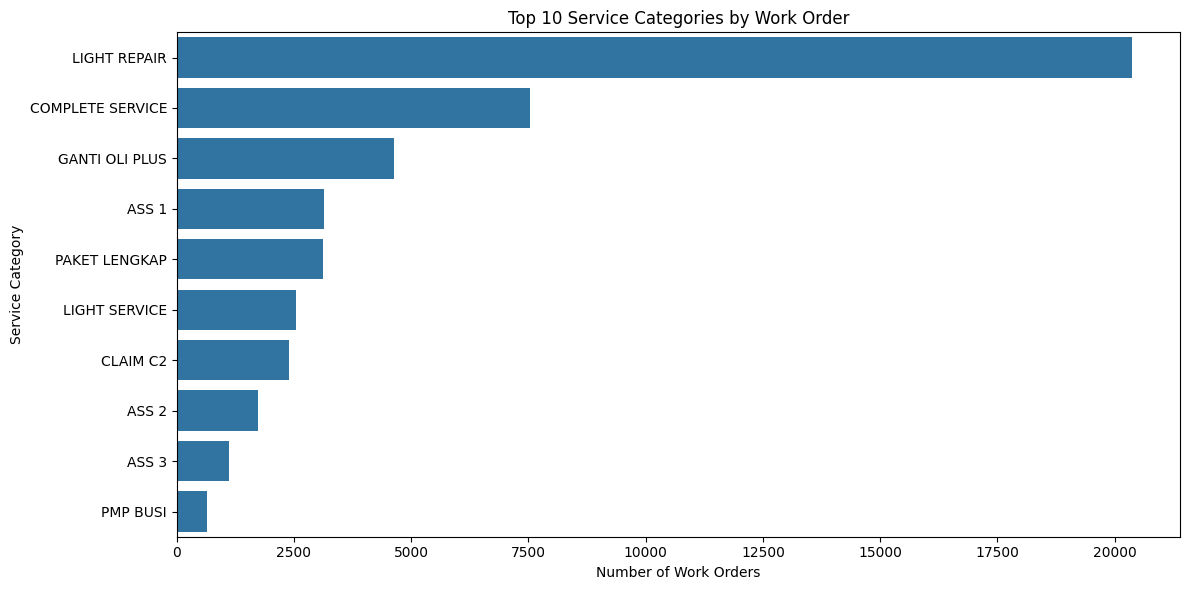

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=service_category_analysis.head(10),
    x="work_order_count",
    y="service_category"
)

plt.title("Top 10 Service Categories by Work Order")
plt.xlabel("Number of Work Orders")
plt.ylabel("Service Category")
plt.tight_layout()
plt.show()

After-sales service demand is primarily concentrated in Light Repair, followed by Complete Service and Ganti Oli Plus. This indicates that routine and relatively light service activities represent a major portion of the observed Work Order volume

#### Service Demand by Vehicle Type

In [ ]:
vehicle_type_analysis = (
    wo_summary
    .groupby("type_motor", dropna=False)
    .agg(
        work_order_count=("woid", "nunique"),
        total_transaction_value=("total_transaction_value", "sum")
    )
    .reset_index()
    .sort_values("work_order_count", ascending=False)
)

display(
    vehicle_type_analysis.head(10)
)

,type_motor,work_order_count,total_transaction_value
34,BEAT SPORTY CBS,3876,"278,425,392.00"
38,BEAT SPORTY CW,3422,"275,526,568.00"
37,BEAT SPORTY CBS ISS DELUXE,2070,"180,500,561.00"
202,VARIO 125 CBS,2062,"204,780,387.00"
36,BEAT SPORTY CBS ISS,1682,"152,942,065.00"
207,VARIO 150,1634,"180,208,372.00"
203,VARIO 125 CBS ISS,1603,"140,615,478.00"
40,BEAT STREET,1524,"102,717,755.00"
140,PCX 160 CBS,1343,"176,044,423.00"
19,BEAT FI CW,1135,"92,763,906.00"


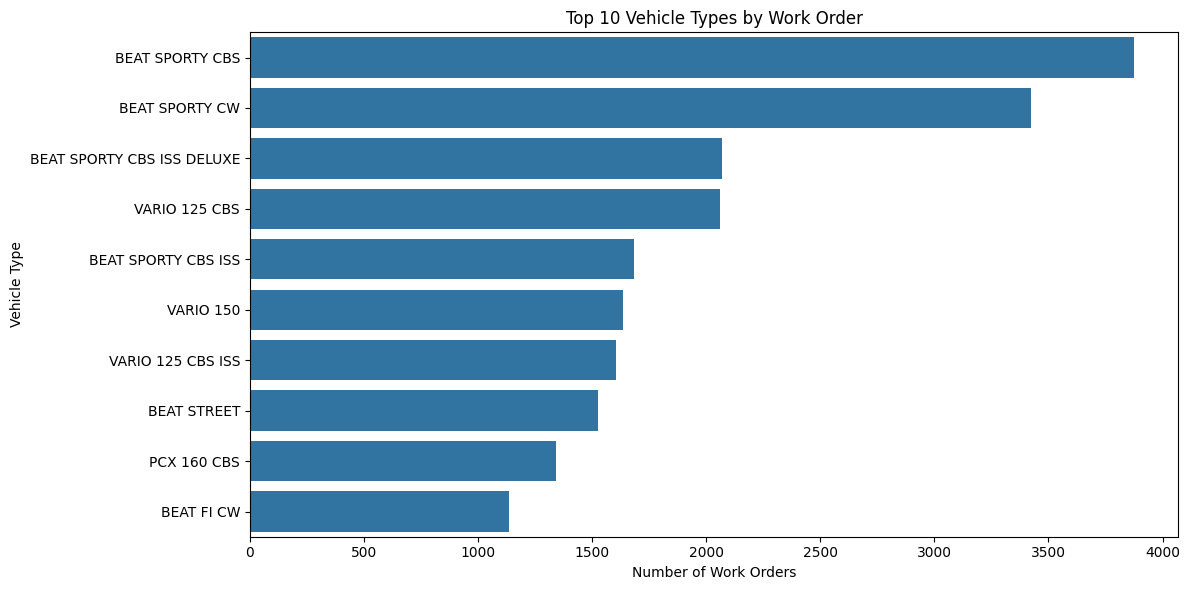

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=vehicle_type_analysis.head(10),
    x="work_order_count",
    y="type_motor"
)

plt.title("Top 10 Vehicle Types by Work Order")
plt.xlabel("Number of Work Orders")
plt.ylabel("Vehicle Type")
plt.tight_layout()
plt.show()

After-sales service demand is concentrated among several high-volume motorcycle models, particularly variants of the BeAT Sporty family. This suggests that vehicle mix is an important factor in understanding service demand and should be considered when evaluating service capacity and spare-part requirements.

#### Service Demand by Location

In [ ]:
location_analysis = (
    wo_summary
    .groupby("location", dropna=False)
    .agg(
        work_order_count=("woid", "nunique"),
        total_transaction_value=("total_transaction_value", "sum")
    )
    .reset_index()
    .sort_values("work_order_count", ascending=False)
)

display(
    location_analysis.head(10)
)

,location,work_order_count,total_transaction_value
65,<NA>,9915,"1,081,922,520.00"
8,KAB. BOGOR,4132,"349,362,315.00"
48,KOTA BANDUNG,3353,"350,958,408.90"
6,KAB. BEKASI,3281,"302,441,808.00"
2,KAB. BANDUNG,2900,"274,098,892.00"
50,KOTA BEKASI,2749,"239,021,807.00"
20,KAB. KARAWANG,2533,"232,617,265.00"
14,KAB. CIREBON,2032,"148,806,007.00"
54,KOTA DEPOK,1664,"169,900,918.00"
35,KAB. SUBANG,1467,"69,265,653.00"


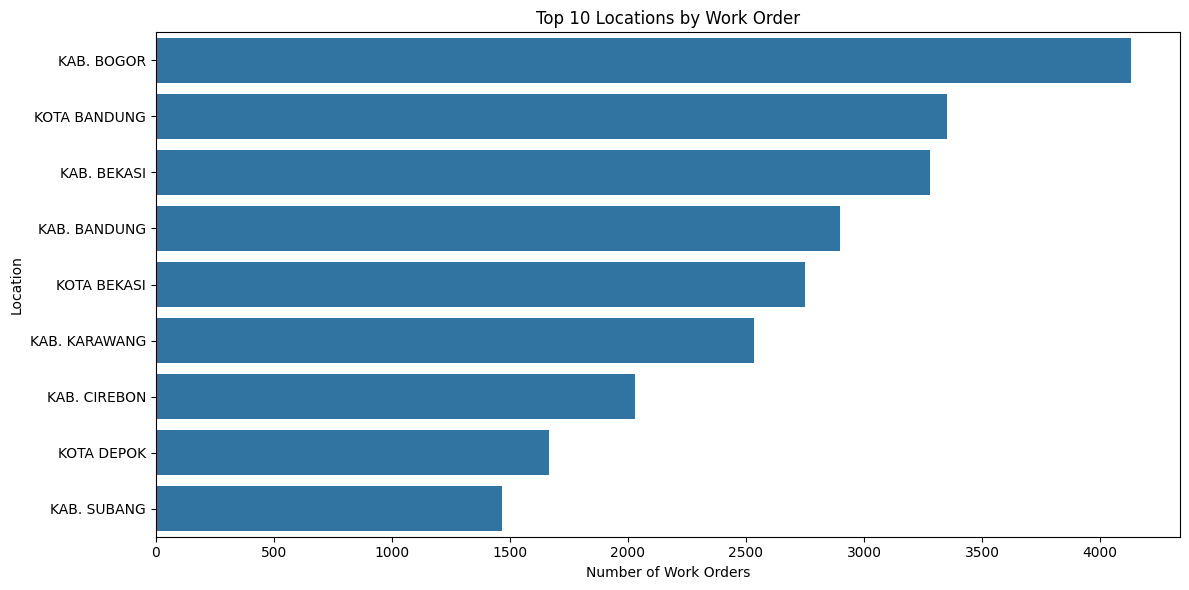

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=location_analysis.head(10),
    x="work_order_count",
    y="location"
)

plt.title("Top 10 Locations by Work Order")
plt.xlabel("Number of Work Orders")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

After-sales service demand is concentrated in several major locations, with Kab. Bogor recording the highest Work Order volume, followed by Kota Bandung and Kab. Bekasi. This indicates that geographic distribution is an important dimension for understanding service demand and operational planning

### Operational Performance

How long does the service process take, and where are potential operational bottlenecks observed

#### Service Duration Distribution

In [ ]:
duration_summary = (
    wo_summary["total_process_hours"]
    .describe()
    .to_frame("total_process_hours")
)

display(duration_summary)

,total_process_hours
count,"45,105.00"
mean,27.22
std,776.52
min,-0.39
25%,0.26
50%,0.78
75%,2.13
max,"33,890.34"


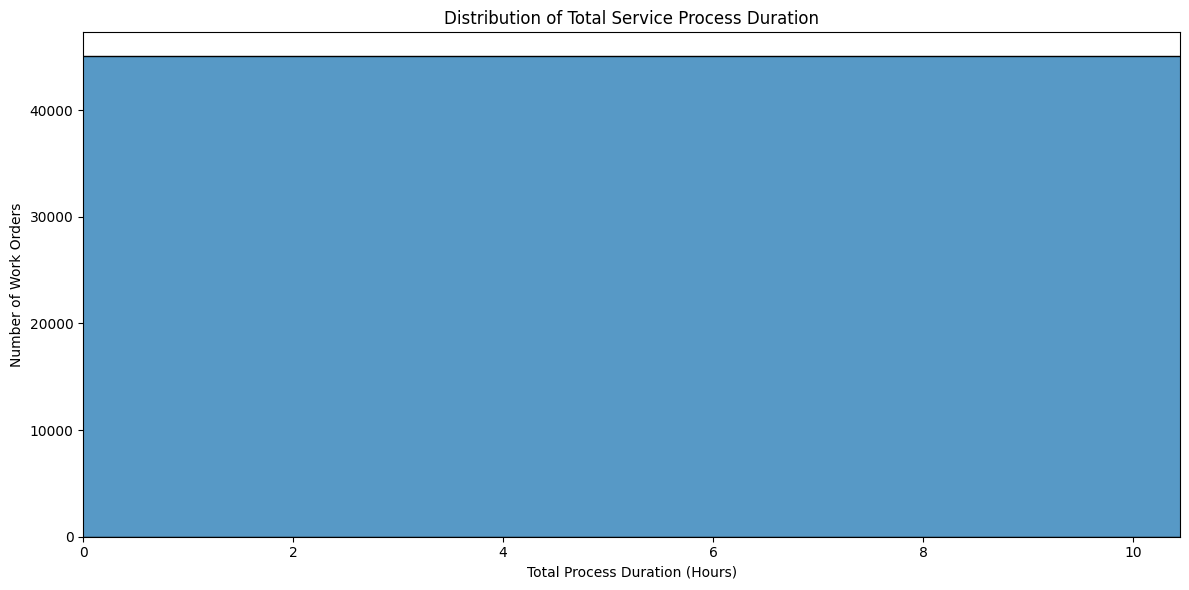

In [ ]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=wo_summary,
    x="total_process_hours",
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Total Service Process Duration")
plt.xlabel("Total Process Duration (Hours)")
plt.ylabel("Number of Work Orders")

plt.xlim(
    0,
    wo_summary["total_process_hours"].quantile(0.95)
)

plt.tight_layout()
plt.show()

In [ ]:
duration = wo_summary["total_process_hours"]

print("Basic statistics:")
display(duration.describe())

print("\nSelected quantiles:")
display(
    duration.quantile(
        [0, 0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.00]
    ).to_frame("total_process_hours")
)

print("\nExact / near-zero duration:")
print("Duration = 0:", (duration == 0).sum())
print("Duration < 0.1 hour:", (duration < 0.1).sum())
print("Duration < 0.5 hour:", (duration < 0.5).sum())
print("Duration < 1 hour:", (duration < 1).sum())

print("\nMissing duration:", duration.isna().sum())

Basic statistics:


,total_process_hours
count,"45,105.00"
mean,27.22
std,776.52
min,-0.39
25%,0.26
50%,0.78
75%,2.13
max,"33,890.34"



Selected quantiles:


,total_process_hours
0.00,-0.39
0.01,0.01
0.05,0.03
0.10,0.07
0.25,0.26
0.50,0.78
0.75,2.13
0.90,4.51
0.95,10.45
0.99,35.33



Exact / near-zero duration:
Duration = 0: 0
Duration < 0.1 hour: 5636
Duration < 0.5 hour: 17217
Duration < 1 hour: 25822

Missing duration: 4031


In [ ]:
duration_check = wo_summary[
    [
        "woid",
        "start_to_finish_hours",
        "finish_to_final_check_hours",
        "final_check_to_payment_hours",
        "total_process_hours"
    ]
].copy()

print("10 smallest total process durations:")
display(
    duration_check
    .sort_values("total_process_hours")
    .head(10)
)

print("\n10 largest total process durations:")
display(
    duration_check
    .sort_values("total_process_hours", ascending=False)
    .head(10)
)

10 smallest total process durations:


,woid,start_to_finish_hours,finish_to_final_check_hours,final_check_to_payment_hours,total_process_hours
20345,WO-07047-25-08-00681,-0.42,0.01,0.02,-0.39
33641,WO-11343-25-08-00782,-0.27,0.03,0.00,-0.23
45507,WO-18616-25-08-00483,-0.14,0.01,0.01,-0.13
45506,WO-18616-25-08-00482,-0.15,0.00,0.01,-0.13
33628,WO-11343-25-08-00769,-0.13,0.01,0.01,-0.11
15549,WO-06298-25-08-00738,-0.18,0.08,0.00,-0.10
40124,WO-15523-25-08-01203,-0.10,0.01,0.01,-0.08
40071,WO-15523-25-08-01150,-0.09,0.01,0.01,-0.08
20192,WO-06979-25-08-00435,-0.10,0.01,0.01,-0.07
29738,WO-09467-25-08-01057,-0.12,0.04,0.02,-0.06



10 largest total process durations:


,woid,start_to_finish_hours,finish_to_final_check_hours,final_check_to_payment_hours,total_process_hours
31417,WO-10064-00018581,0.00,NaN,NaN,"33,890.34"
16248,WO-06490-00016552,0.00,0.09,"32,164.87","32,164.96"
40666,WO-15877-00014642,0.00,0.12,"31,009.28","31,009.40"
40667,WO-15877-00019435,0.00,0.77,"29,228.95","29,229.72"
37531,WO-13262-00001742,0.00,0.43,"29,214.57","29,215.00"
37532,WO-13262-00001743,0.00,0.41,"29,214.56","29,214.98"
3688,WO-00908-00011011,0.00,0.00,"29,136.29","29,136.30"
37533,WO-13262-00001828,0.00,24.81,"29,093.51","29,118.32"
37534,WO-13262-00001848,0.00,1.26,"29,093.53","29,094.79"
37535,WO-13262-00001850,0.00,1.26,"29,093.51","29,094.77"


In [ ]:
print("Cell started...")

wo_summary["start_to_finish_hours_clean"] = np.where(
    wo_summary["start_to_finish_hours"] >= 0,
    wo_summary["start_to_finish_hours"],
    np.nan
)

wo_summary["finish_to_final_check_hours_clean"] = np.where(
    wo_summary["finish_to_final_check_hours"] >= 0,
    wo_summary["finish_to_final_check_hours"],
    np.nan
)

wo_summary["operational_duration_hours"] = (
    wo_summary["start_to_finish_hours_clean"].fillna(0)
    + wo_summary["finish_to_final_check_hours_clean"].fillna(0)
)

both_missing = (
    wo_summary["start_to_finish_hours_clean"].isna()
    & wo_summary["finish_to_final_check_hours_clean"].isna()
)

wo_summary.loc[both_missing, "operational_duration_hours"] = np.nan

print("Operational duration created.")
print()
print("Count:", wo_summary["operational_duration_hours"].count())
print("Missing:", wo_summary["operational_duration_hours"].isna().sum())
print("Median:", wo_summary["operational_duration_hours"].median())
print("Maximum:", wo_summary["operational_duration_hours"].max())

Cell started...
Operational duration created.

Count: 47335
Missing: 1801
Median: 0.4436111111111111
Maximum: 6074.555833333334


In [ ]:
display(
    wo_summary[
        [
            "woid",
            "start_to_finish_hours_clean",
            "finish_to_final_check_hours_clean",
            "operational_duration_hours"
        ]
    ]
    .sort_values("operational_duration_hours", ascending=False)
    .head(5)
)

,woid,start_to_finish_hours_clean,finish_to_final_check_hours_clean,operational_duration_hours
2451,WO-00662-24-12-00441,0.00,"6,074.55","6,074.56"
2452,WO-00662-25-01-00414,0.00,"5,327.71","5,327.71"
33272,WO-10922-25-04-00458,0.00,"3,066.69","3,066.69"
2453,WO-00662-25-04-00937,0.00,"2,835.18","2,835.18"
19516,WO-06945-25-06-00887,0.00,"1,409.27","1,409.27"


In [ ]:
# Extreme values above P99 are excluded from duration analysis,
# while the original data remains unchanged.

duration_valid = wo_summary[
    wo_summary["operational_duration_hours"] >= 0
]["operational_duration_hours"]

p99_duration = duration_valid.quantile(0.99)

wo_summary["operational_duration_eda"] = np.where(
    wo_summary["operational_duration_hours"].between(
        0, p99_duration
    ),
    wo_summary["operational_duration_hours"],
    np.nan
)

print(f"P99 operational duration: {p99_duration:.2f} hours")

print(
    "Valid duration for EDA:",
    wo_summary["operational_duration_eda"].notna().sum()
)

print(
    "Excluded from duration analysis:",
    wo_summary["operational_duration_eda"].isna().sum()
)

display(
    wo_summary["operational_duration_eda"].describe()
)

P99 operational duration: 22.96 hours
Valid duration for EDA: 46861
Excluded from duration analysis: 2275


,operational_duration_eda
count,"46,861.00"
mean,1.32
std,2.81
min,0.00
25%,0.11
50%,0.43
75%,1.29
max,22.94


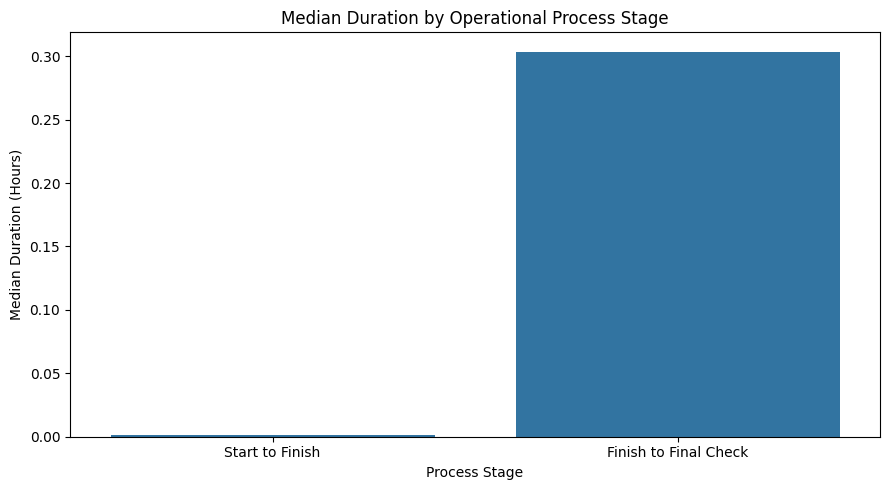

,process_stage,median_hours
0,Start to Finish,0.00
1,Finish to Final Check,0.30


In [ ]:
process_stage_summary = pd.DataFrame({
    "process_stage": [
        "Start to Finish",
        "Finish to Final Check"
    ],
    "median_hours": [
        wo_summary["start_to_finish_hours_clean"].median(),
        wo_summary["finish_to_final_check_hours_clean"].median()
    ]
})

plt.figure(figsize=(9, 5))

sns.barplot(
    data=process_stage_summary,
    x="process_stage",
    y="median_hours"
)

plt.title("Median Duration by Operational Process Stage")
plt.xlabel("Process Stage")
plt.ylabel("Median Duration (Hours)")
plt.tight_layout()
plt.show()

display(process_stage_summary)

The Finish-to-Final Check stage represents the longer typical operational stage, with a median duration of approximately 0.30 hours (18 minutes), while the median Start-to-Finish duration is close to zero

#### Operational Duration by Service Category

In [ ]:
duration_by_service = (
    wo_summary
    .groupby("service_category", dropna=False)
    .agg(
        work_order_count=("woid", "nunique"),
        median_duration_hours=("operational_duration_eda", "median")
    )
    .reset_index()
    .sort_values("median_duration_hours", ascending=False)
)

display(
    duration_by_service.head(10)
)

,service_category,work_order_count,median_duration_hours
13,PMP BUSI,645,0.66
15,PMP DRIVE BELT,107,0.66
10,PAKET LAIN,347,0.56
11,PAKET LENGKAP,3114,0.54
5,COMPLETE SERVICE,7525,0.49
16,PMP FILTER UDARA,347,0.47
8,LIGHT REPAIR,20377,0.46
14,PMP COOLANT,329,0.46
7,HEAVY REPAIR,51,0.43
9,LIGHT SERVICE,2534,0.43


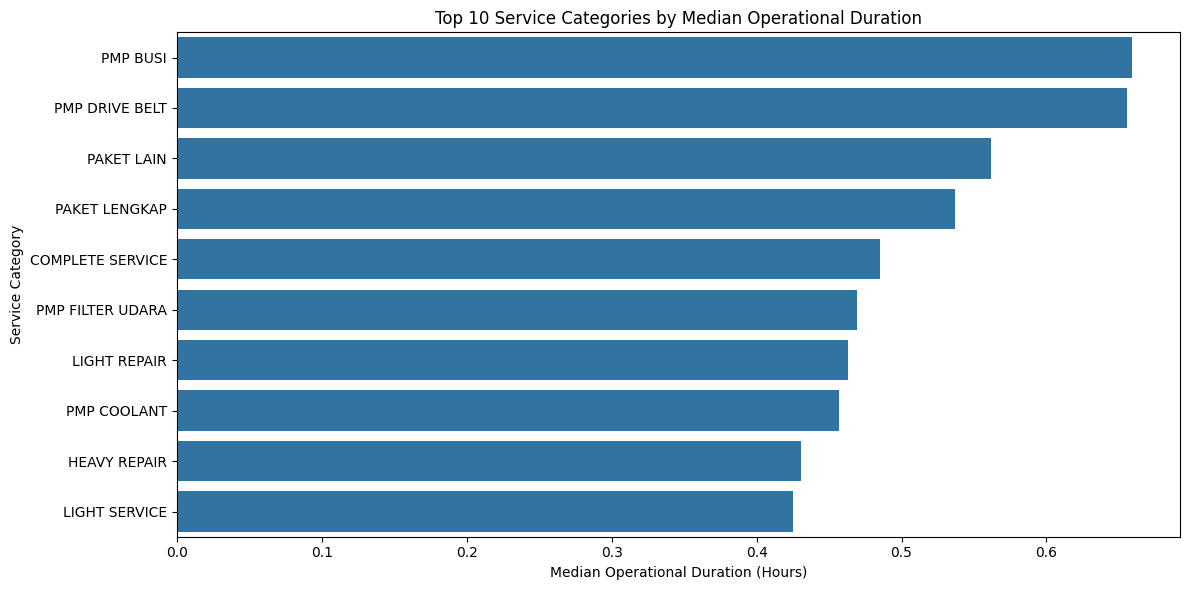

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=duration_by_service.head(10),
    x="median_duration_hours",
    y="service_category"
)

plt.title("Top 10 Service Categories by Median Operational Duration")
plt.xlabel("Median Operational Duration (Hours)")
plt.ylabel("Service Category")
plt.tight_layout()
plt.show()

The median operational service duration is approximately 0.43 hours (26 minutes). The Finish-to-Final Check stage has the longer typical duration at around 0.30 hours (18 minutes), indicating that this stage may require closer operational attention. At the service-category level, Paket Lengkap and Complete Service combine relatively higher median durations with substantial Work Order volumes, making them more relevant for further operational monitoring than low-volume categories with high median durations.

* How long?
→ Median 0.43 jam / ±26 menit.
* Where are potential bottlenecks?
→ Finish → Final Check, dengan perhatian khusus pada kategori Paket Lengkap dan Complete Service karena kombinasi volume dan durasinya.

### Promotion & Booking

How are promotions and booking activities associated with after-sales service activity?

#### Promotion vs Non-Promotion

In [ ]:
promotion_analysis = (
    wo_summary
    .groupby("has_promotion")
    .agg(
        work_order_count=("woid", "nunique"),
        total_transaction_value=("total_transaction_value", "sum"),
        average_transaction_value=("total_transaction_value", "mean")
    )
    .reset_index()
)

promotion_analysis["promotion_status"] = promotion_analysis["has_promotion"].map({
    False: "Without Promotion",
    True: "With Promotion"
})

promotion_analysis = promotion_analysis[
    [
        "promotion_status",
        "work_order_count",
        "total_transaction_value",
        "average_transaction_value"
    ]
]

display(promotion_analysis)

,promotion_status,work_order_count,total_transaction_value,average_transaction_value
0,Without Promotion,46875,"4,141,018,372.00","88,341.73"
1,With Promotion,2261,"332,837,861.90","147,208.25"


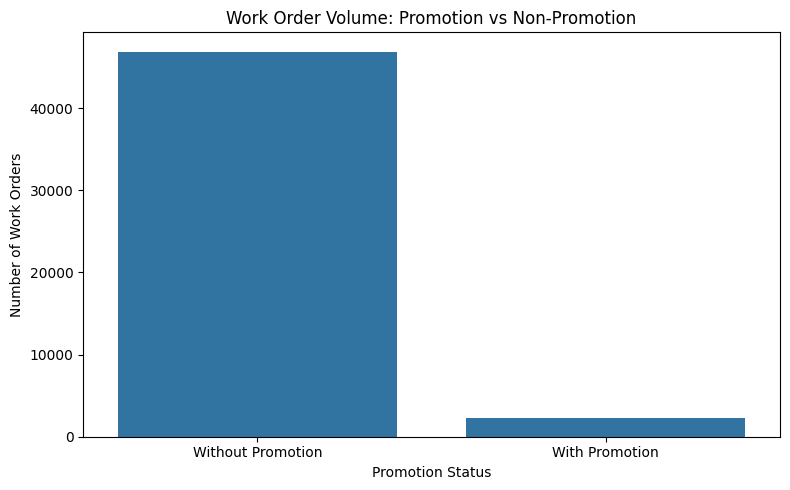

In [ ]:
# Promotion vs Non-Promotion — Work Order Volume

plt.figure(figsize=(8, 5))

sns.barplot(
    data=promotion_analysis,
    x="promotion_status",
    y="work_order_count"
)

plt.title("Work Order Volume: Promotion vs Non-Promotion")
plt.xlabel("Promotion Status")
plt.ylabel("Number of Work Orders")
plt.tight_layout()
plt.show()

Work Orders associated with promotions show a higher average transaction value than non-promotion Work Orders, although promotion-associated Work Orders represent only a small portion of total service activity.

#### Booking vs Non-Booking

In [ ]:
# Booking vs Non-Booking

booking_analysis = (
    wo_summary
    .groupby("has_booking")
    .agg(
        work_order_count=("woid", "nunique"),
        total_transaction_value=("total_transaction_value", "sum"),
        average_transaction_value=("total_transaction_value", "mean")
    )
    .reset_index()
)

booking_analysis["booking_status"] = booking_analysis["has_booking"].map({
    False: "Without Booking",
    True: "With Booking"
})

booking_analysis = booking_analysis[
    [
        "booking_status",
        "work_order_count",
        "total_transaction_value",
        "average_transaction_value"
    ]
]

display(booking_analysis)

,booking_status,work_order_count,total_transaction_value,average_transaction_value
0,Without Booking,42542,"4,176,364,394.00","98,170.38"
1,With Booking,6594,"297,491,839.90","45,115.54"


Booked Work Orders represent a meaningful portion of service activity (13.4%), but their average transaction value is substantially lower than non-booked Work Orders.

#### Service Channel Analysis

In [ ]:
# Check source consistency at Work Order level

source_per_wo = (
    workorder_enriched
    .groupby("woid")["source"]
    .nunique()
)

print(
    "WO > 1 source:",
    (source_per_wo > 1).sum()
)

print(
    "WO with source:",
    (source_per_wo > 0).sum()
)

print(
    "WO without source:",
    (source_per_wo == 0).sum()
)

WO > 1 source: 0
WO with source: 6594
WO without source: 42542


In [ ]:
# Check source coverage against total Work Orders

print("Unique WO in wo_summary:",
      wo_summary["woid"].nunique())

print("Unique WO in workorder_enriched:",
      workorder_enriched["woid"].nunique())

print("WO represented in source_per_wo:",
      len(source_per_wo))

print("Missing WO in source_per_wo:",
      source_per_wo.isna().sum())

Unique WO in wo_summary: 49136
Unique WO in workorder_enriched: 49136
WO represented in source_per_wo: 49136
Missing WO in source_per_wo: 0


In [ ]:
# 7.3.3 Service Channel Analysis

wo_channel = (
    workorder_enriched
    .groupby("woid", as_index=False)
    .agg(
        source=("source", "first")
    )
)

wo_channel["service_channel"] = (
    wo_channel["source"]
    .fillna("No Channel Recorded")
)

channel_analysis = (
    wo_summary[
        [
            "woid",
            "total_transaction_value"
        ]
    ]
    .merge(
        wo_channel[
            [
                "woid",
                "service_channel"
            ]
        ],
        on="woid",
        how="left"
    )
    .groupby("service_channel")
    .agg(
        work_order_count=("woid", "nunique"),
        total_transaction_value=("total_transaction_value", "sum"),
        average_transaction_value=("total_transaction_value", "mean")
    )
    .reset_index()
    .sort_values("work_order_count", ascending=False)
)

display(channel_analysis)

,service_channel,work_order_count,total_transaction_value,average_transaction_value
2,No Channel Recorded,42542,"4,176,364,394.00","98,170.38"
1,MOBILESOBI,5018,"222,203,639.90","44,281.32"
0,HOTLINE,1575,"75,229,200.00","47,764.57"
3,WEBSITE DAYA AUTO,1,"59,000.00","59,000.00"


Among Work Orders with recorded service channels, MOBILESOBI accounts for the largest volume, followed by HOTLINE. However, most Work Orders have no recorded channel, limiting the completeness of channel-level performance comparison.

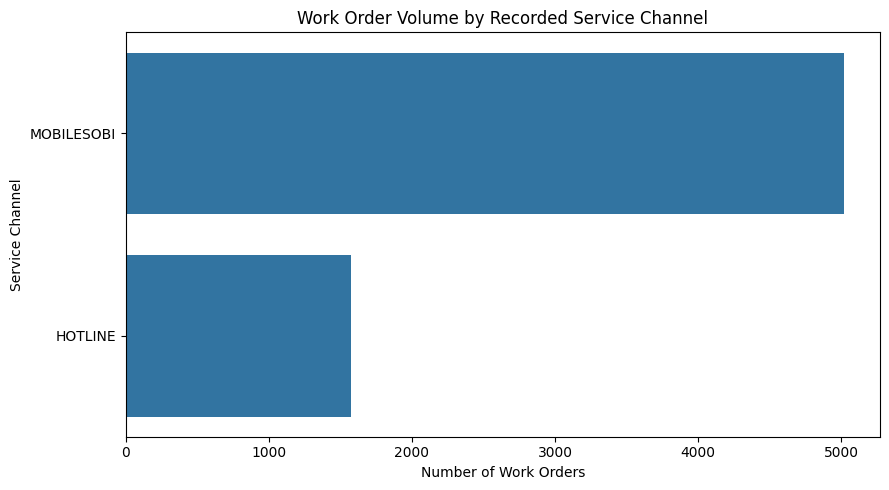

In [ ]:

channel_chart = channel_analysis[
    ~channel_analysis["service_channel"].isin(
        ["No Channel Recorded", "WEBSITE DAYA AUTO"]
    )
].copy()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=channel_chart,
    x="work_order_count",
    y="service_channel"
)

plt.title("Work Order Volume by Recorded Service Channel")
plt.xlabel("Number of Work Orders")
plt.ylabel("Service Channel")
plt.tight_layout()
plt.show()

Promotion-associated Work Orders show higher average transaction value, while booked Work Orders show lower average transaction value than their respective counterparts. Among recorded service channels, MOBILESOBI has the highest Work Order volume. However, the large proportion of Work Orders without recorded channel information should be considered when interpreting channel performance.


### Spare - Part Demand

Which spare parts and part groups contribute most to spare-part utilization and value?

In [ ]:
spare_part_detail = (
    workorder_enriched[
        workorder_enriched["kelompok_barang"].notna()
    ][
        [
            "woid",
            "partid",
            "kelompok_barang",
            "spare_part_value"
        ]
    ]
    .drop_duplicates(
        subset=["woid", "partid"]
    )
)

spare_group_analysis = (
    spare_part_detail
    .groupby("kelompok_barang")
    .agg(
        work_order_count=("woid", "nunique"),
        unique_part_count=("partid", "nunique"),
        total_spare_part_value=("spare_part_value", "sum")
    )
    .reset_index()
    .sort_values(
        "total_spare_part_value",
        ascending=False
    )
)

display(
    spare_group_analysis.head(10)
)

,kelompok_barang,work_order_count,unique_part_count,total_spare_part_value
23,OIL,16359,48,"819,425,600.00"
6,BRAKE,2286,85,"196,845,613.00"
4,BATT,482,8,"122,817,360.00"
17,ELECT,987,199,"122,302,300.00"
3,AHM,1599,317,"119,310,250.00"
40,TIRE,399,24,"117,488,820.00"
5,BLDRV,568,28,"88,395,575.00"
15,DISK,403,58,"83,058,225.00"
1,ACCEC,480,15,"66,644,000.00"
16,EC,940,23,"55,506,790.00"


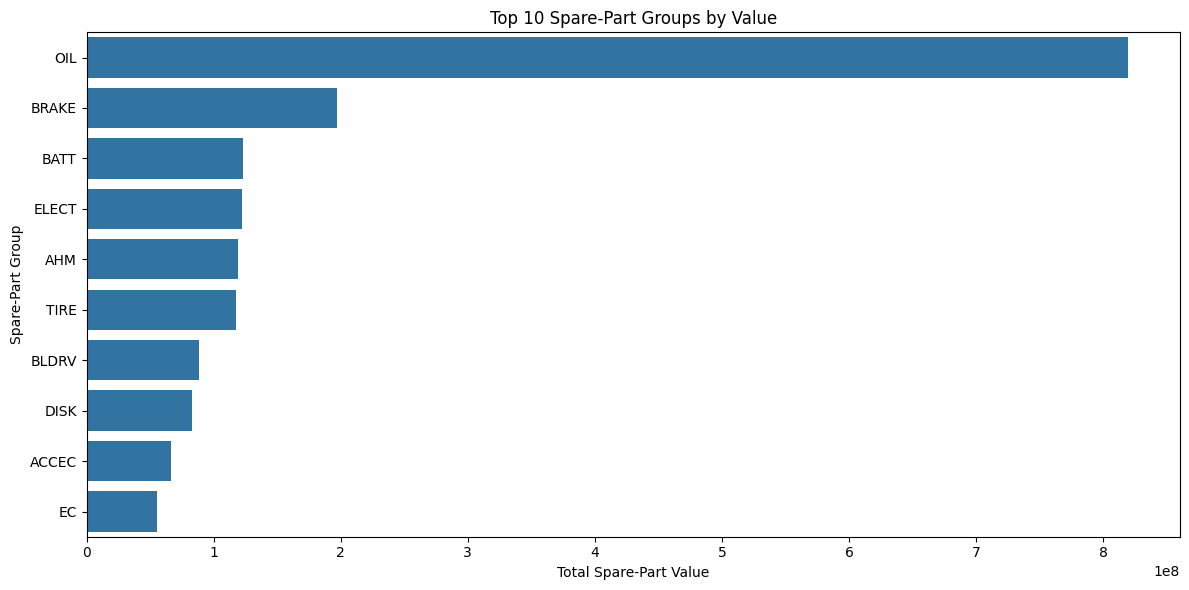

In [ ]:
# Top 10 Spare-Part Groups by Value

plt.figure(figsize=(12, 6))

sns.barplot(
    data=spare_group_analysis.head(10),
    x="total_spare_part_value",
    y="kelompok_barang"
)

plt.title("Top 10 Spare-Part Groups by Value")
plt.xlabel("Total Spare-Part Value")
plt.ylabel("Spare-Part Group")
plt.tight_layout()
plt.show()

#### Top Individual Spare Parts

In [ ]:
spare_part_detail = (
    workorder_enriched[
        workorder_enriched["partid"].notna()
    ][
        [
            "woid",
            "partid",
            "deskripsi1",
            "spare_part_value"
        ]
    ]
    .drop_duplicates(
        subset=["woid", "partid"]
    )
)

part_analysis = (
    spare_part_detail
    .groupby(
        ["partid", "deskripsi1"],
        dropna=False
    )
    .agg(
        work_order_count=("woid", "nunique"),
        total_spare_part_value=("spare_part_value", "sum")
    )
    .reset_index()
    .sort_values(
        "total_spare_part_value",
        ascending=False
    )
)

display(
    part_analysis.head(10)
)

,partid,deskripsi1,work_order_count,total_spare_part_value
282,082342MBK0LZ0,"SPX2 10W30 SLMB 0,8L REP",3674,"225,335,950.00"
267,082322MBK3LN1,"MPX2 10W30 SLMB 0,65L IDE E",5824,"217,030,000.00"
259,082322MBK0LN1,"OLI MPX2 10W30 SL 0,8L IDE",2583,"129,101,500.00"
275,08232M99K0LN5,"MPX2 10W30 SLMB 0,8L CAS",1465,"77,467,000.00"
1063,31500KZR602,BATTERY(GTZ6V),209,"64,721,620.00"
1244,43130KZL930,BRAKE SHOE,851,"47,244,425.00"
285,082342MBK8LZ0,"SPX2 10W30 SLMB 0,65L REP",710,"43,336,500.00"
1264,44711K59A12,TIRE FR TL (80/90-14),128,"35,246,815.00"
155,06455KVBT01,PAD SET FR,568,"34,401,425.00"
1226,42711K59A12,TIRE RR TL (90/90-14),106,"31,148,060.00"


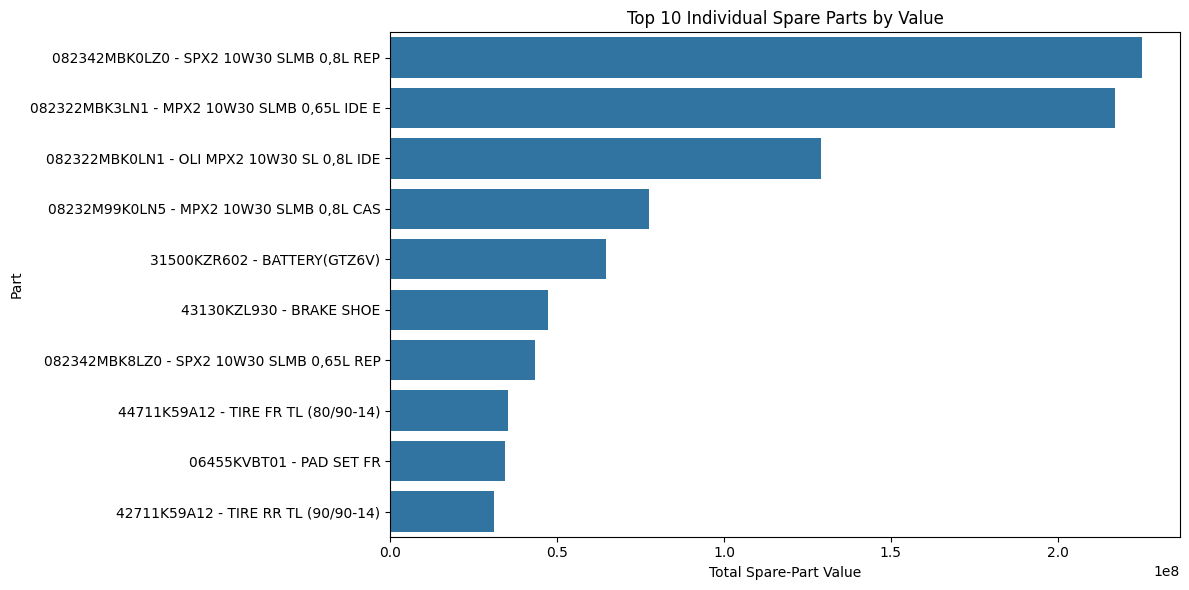

In [ ]:
# Top 10 Individual Spare Parts by Value

top_parts = part_analysis.head(10).copy()

top_parts["part_label"] = (
    top_parts["partid"].astype(str)
    + " - "
    + top_parts["deskripsi1"].fillna("No Description").astype(str)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_parts,
    x="total_spare_part_value",
    y="part_label"
)

plt.title("Top 10 Individual Spare Parts by Value")
plt.xlabel("Total Spare-Part Value")
plt.ylabel("Part")
plt.tight_layout()
plt.show()

The OIL spare-part group is the largest contributor to spare-part value and Work Order utilization. At the individual-part level, several oil products dominate the highest-value parts, while battery, brake, and tire-related parts also contribute significantly.

## Business Analysis

#### Business Analysis — Service Performance

In [ ]:
service_business_analysis = (
    wo_summary
    .groupby("service_category", dropna=False)
    .agg(
        work_order_count=("woid", "nunique"),
        total_transaction_value=("total_transaction_value", "sum"),
        average_transaction_value=("total_transaction_value", "mean"),
        median_transaction_value=("total_transaction_value", "median")
    )
    .reset_index()
    .sort_values(
        "total_transaction_value",
        ascending=False
    )
)

display(
    service_business_analysis.head(10)
)

,service_category,work_order_count,total_transaction_value,average_transaction_value,median_transaction_value
8,LIGHT REPAIR,20377,"1,647,670,363.90","80,859.32","20,000.00"
5,COMPLETE SERVICE,7525,"1,154,555,801.00","153,429.34","128,100.00"
6,GANTI OLI PLUS,4636,"445,584,774.00","96,114.06","70,500.00"
11,PAKET LENGKAP,3114,"420,125,900.00","134,915.19","116,375.00"
9,LIGHT SERVICE,2534,"241,851,545.00","95,442.60","60,500.00"
4,CLAIM C2,2395,"139,969,385.00","58,442.33",0.00
1,ASS 2,1734,"64,709,500.00","37,318.05","50,000.00"
12,PAKET RINGAN,196,"57,308,620.00","292,390.92","211,000.00"
2,ASS 3,1111,"49,008,000.00","44,111.61","50,000.00"
16,PMP FILTER UDARA,347,"48,056,850.00","138,492.36","75,500.00"


LIGHT REPAIR is the primary service-volume driver, while COMPLETE SERVICE combines substantial service volume with a higher average transaction value. PAKET LENGKAP also shows relatively high transaction value with meaningful volume. This suggests that service categories should be evaluated using both demand volume and transaction value rather than volume alone.

#### Spare Part Management

In [ ]:
spare_business_analysis = (
    spare_group_analysis
    .copy()
)

display(
    spare_business_analysis.head(10)
)

,kelompok_barang,work_order_count,unique_part_count,total_spare_part_value
23,OIL,16359,48,"819,425,600.00"
6,BRAKE,2286,85,"196,845,613.00"
4,BATT,482,8,"122,817,360.00"
17,ELECT,987,199,"122,302,300.00"
3,AHM,1599,317,"119,310,250.00"
40,TIRE,399,24,"117,488,820.00"
5,BLDRV,568,28,"88,395,575.00"
15,DISK,403,58,"83,058,225.00"
1,ACCEC,480,15,"66,644,000.00"
16,EC,940,23,"55,506,790.00"


OIL is the primary spare-part business driver, combining the highest Work Order utilization and value contribution. BRAKE also shows strong utilization and value, while BATT and TIRE contribute substantial value despite lower utilization. This suggests that spare-part planning should consider both demand frequency and value contribution rather than utilization alone

#### Customer Engagement & Channel

In [ ]:
engagement_analysis = (
    wo_summary
    .groupby(
        ["has_promotion", "has_booking"]
    )
    .agg(
        work_order_count=("woid", "nunique"),
        total_transaction_value=("total_transaction_value", "sum"),
        average_transaction_value=("total_transaction_value", "mean")
    )
    .reset_index()
)

# Create engagement segment
engagement_analysis["engagement_segment"] = (
    engagement_analysis.apply(
        lambda row:
            "Promotion + Booking"
            if row["has_promotion"] and row["has_booking"]
            else "Promotion + No Booking"
            if row["has_promotion"] and not row["has_booking"]
            else "No Promotion + Booking"
            if not row["has_promotion"] and row["has_booking"]
            else "No Promotion + No Booking",
        axis=1
    )
)

display(
    engagement_analysis[
        [
            "engagement_segment",
            "work_order_count",
            "total_transaction_value",
            "average_transaction_value"
        ]
    ]
    .sort_values(
        "work_order_count",
        ascending=False
    )
)

,engagement_segment,work_order_count,total_transaction_value,average_transaction_value
0,No Promotion + No Booking,40673,"3,882,723,213.00","95,461.93"
1,No Promotion + Booking,6202,"258,295,159.00","41,647.07"
2,Promotion + No Booking,1869,"293,641,181.00","157,111.39"
3,Promotion + Booking,392,"39,196,680.90","99,991.53"


Promotion-associated Work Orders show higher transaction values, particularly among non-booked transactions. In contrast, booked Work Orders without promotion have the lowest average transaction value. This suggests that promotion and booking should not be evaluated independently when assessing customer engagement patterns.


## Business Case

#### After-Sales Engagement Segmentation


In [ ]:
wo_summary["engagement_segment"] = (
    wo_summary.apply(
        lambda row:
            "Promotion + Booking"
            if row["has_promotion"] and row["has_booking"]
            else "Promotion + No Booking"
            if row["has_promotion"] and not row["has_booking"]
            else "No Promotion + Booking"
            if not row["has_promotion"] and row["has_booking"]
            else "No Promotion + No Booking",
        axis=1
    )
)

print("Engagement segment created.")

display(
    wo_summary[
        [
            "woid",
            "has_promotion",
            "has_booking",
            "engagement_segment",
            "total_transaction_value"
        ]
    ].head(10)
)

Engagement segment created.


,woid,has_promotion,has_booking,engagement_segment,total_transaction_value
0,JR-03826-25-08-00019,False,False,No Promotion + No Booking,0.00
1,JR-03826-25-08-00020,False,False,No Promotion + No Booking,0.00
2,JR-06298-25-08-00007,False,False,No Promotion + No Booking,0.00
3,JR-13311-25-08-00002,False,False,No Promotion + No Booking,"1,080,000.00"
4,VST-00309-25-08-00109,False,False,No Promotion + No Booking,0.00
5,VST-00309-25-08-00110,False,False,No Promotion + No Booking,0.00
6,VST-00309-25-08-00111,False,False,No Promotion + No Booking,0.00
7,VST-00309-25-08-00112,False,False,No Promotion + No Booking,0.00
8,VST-00309-25-08-00113,False,False,No Promotion + No Booking,0.00
9,VST-00309-25-08-00114,False,False,No Promotion + No Booking,0.00


#### Add Service Channel

In [ ]:
wo_summary = wo_summary.merge(
    wo_channel[["woid", "service_channel"]],
    on="woid",
    how="left"
)

print("Service channel added.")

display(
    wo_summary[
        [
            "woid",
            "service_channel",
            "engagement_segment",
            "total_transaction_value"
        ]
    ].head(10)
)

Service channel added.


,woid,service_channel,engagement_segment,total_transaction_value
0,JR-03826-25-08-00019,No Channel Recorded,No Promotion + No Booking,0.00
1,JR-03826-25-08-00020,No Channel Recorded,No Promotion + No Booking,0.00
2,JR-06298-25-08-00007,No Channel Recorded,No Promotion + No Booking,0.00
3,JR-13311-25-08-00002,No Channel Recorded,No Promotion + No Booking,"1,080,000.00"
4,VST-00309-25-08-00109,No Channel Recorded,No Promotion + No Booking,0.00
5,VST-00309-25-08-00110,No Channel Recorded,No Promotion + No Booking,0.00
6,VST-00309-25-08-00111,No Channel Recorded,No Promotion + No Booking,0.00
7,VST-00309-25-08-00112,No Channel Recorded,No Promotion + No Booking,0.00
8,VST-00309-25-08-00113,No Channel Recorded,No Promotion + No Booking,0.00
9,VST-00309-25-08-00114,No Channel Recorded,No Promotion + No Booking,0.00


#### Engagement Segment Analysis

In [ ]:
engagement_segment_analysis = (
    wo_summary
    .groupby("engagement_segment")
    .agg(
        work_order_count=("woid", "nunique"),
        total_transaction_value=("total_transaction_value", "sum"),
        average_transaction_value=("total_transaction_value", "mean")
    )
    .reset_index()
    .sort_values("work_order_count", ascending=False)
)

display(engagement_segment_analysis)

,engagement_segment,work_order_count,total_transaction_value,average_transaction_value
1,No Promotion + No Booking,40673,"3,882,723,213.00","95,461.93"
0,No Promotion + Booking,6202,"258,295,159.00","41,647.07"
3,Promotion + No Booking,1869,"293,641,181.00","157,111.39"
2,Promotion + Booking,392,"39,196,680.90","99,991.53"


#### Engagement Segment by Service Channel

In [ ]:
segment_channel_analysis = (
    wo_summary
    .groupby(["service_channel", "engagement_segment"])
    .agg(
        work_order_count=("woid", "nunique"),
        total_transaction_value=("total_transaction_value", "sum"),
        average_transaction_value=("total_transaction_value", "mean")
    )
    .reset_index()
    .sort_values(
        ["service_channel", "work_order_count"],
        ascending=[True, False]
    )
)

display(segment_channel_analysis)

,service_channel,engagement_segment,work_order_count,total_transaction_value,average_transaction_value
0,HOTLINE,No Promotion + Booking,1550,"71,137,250.00","45,895.00"
1,HOTLINE,Promotion + Booking,25,"4,091,950.00","163,678.00"
2,MOBILESOBI,No Promotion + Booking,4651,"187,098,909.00","40,227.67"
3,MOBILESOBI,Promotion + Booking,367,"35,104,730.90","95,653.22"
4,No Channel Recorded,No Promotion + No Booking,40673,"3,882,723,213.00","95,461.93"
5,No Channel Recorded,Promotion + No Booking,1869,"293,641,181.00","157,111.39"
6,WEBSITE DAYA AUTO,No Promotion + Booking,1,"59,000.00","59,000.00"


## Data Modelling

#### Grain Validation

In [ ]:
print("Rows in wo_summary :", len(wo_summary))
print("Unique woid        :", wo_summary["woid"].nunique())
print("Duplicate woid     :", wo_summary["woid"].duplicated().sum())

print("\nExpected grain: 1 row = 1 Work Order")

Rows in wo_summary : 49136
Unique woid        : 49136
Duplicate woid     : 0

Expected grain: 1 row = 1 Work Order


#### Relationship Part Key Validation

In [ ]:
print("Rows in masterparts_clean :", len(masterparts_clean))
print("Unique part_number        :", masterparts_clean["part_number"].nunique())
print("Duplicate part_number     :", masterparts_clean["part_number"].duplicated().sum())
print("Missing part_number       :", masterparts_clean["part_number"].isna().sum())

print("\nExpected grain: 1 row = 1 Part Number")

Rows in masterparts_clean : 61970
Unique part_number        : 61970
Duplicate part_number     : 0
Missing part_number       : 0

Expected grain: 1 row = 1 Part Number


#### Validate Work Order to Part Relationship

In [ ]:
wo_part_relationship = (
    workorder_enriched[
        ["woid", "partid", "kelompok_barang", "deskripsi1"]
    ]
    .dropna(subset=["partid"])
    .drop_duplicates(subset=["woid", "partid"])
)

print("Unique Work Order-Part combinations :", len(wo_part_relationship))
print("Unique Work Orders with Part        :", wo_part_relationship["woid"].nunique())
print("Unique Part Numbers used            :", wo_part_relationship["partid"].nunique())

print("\nExpected relationship:")
print("1 Work Order -> Many Part Numbers")
print("1 Part Number -> Many Work Orders")

Unique Work Order-Part combinations : 36398
Unique Work Orders with Part        : 21395
Unique Part Numbers used            : 1915

Expected relationship:
1 Work Order -> Many Part Numbers
1 Part Number -> Many Work Orders


#### Create Work Order Part Bridge Table

In [ ]:
wo_part_bridge = (
    workorder_enriched[
        ["woid", "partid", "kelompok_barang", "deskripsi1", "spare_part_value"]
    ]
    .dropna(subset=["partid"])
    .drop_duplicates(subset=["woid", "partid"])
    .reset_index(drop=True)
)

print("Bridge table created.")
print("Rows :", len(wo_part_bridge))
print("Unique WO :", wo_part_bridge["woid"].nunique())
print("Unique Part :", wo_part_bridge["partid"].nunique())

display(wo_part_bridge.head(10))

Bridge table created.
Rows : 36398
Unique WO : 21395
Unique Part : 1915


,woid,partid,kelompok_barang,deskripsi1,spare_part_value
0,WO-17582-25-08-00294,082322MBK2LN0,OIL,"MPX2 10W30 SLMB 0,8L REP O","59,000.00"
1,WO-06829-25-08-00822,082322MBK3LN1,OIL,"MPX2 10W30 SLMB 0,65L IDE E",0.00
2,WO-17582-25-08-00300,082322MBK2LN0,OIL,"MPX2 10W30 SLMB 0,8L REP O","59,000.00"
3,WO-17826-25-08-00942,082322MBK3LN1,OIL,"MPX2 10W30 SLMB 0,65L IDE E","50,000.00"
4,WO-00203-25-08-00659,082322MBK3LN1,OIL,"MPX2 10W30 SLMB 0,65L IDE E",0.00
5,WO-00998-25-08-00751,06455KREK02,BRAKE,"PAD SET, FR","121,500.00"
6,WO-00998-25-08-00751,082342MBK0LZ0,OIL,"SPX2 10W30 SLMB 0,8L REP","70,500.00"
7,WO-00998-25-08-00751,08294M99Z8YN1,GMO,SCOOTER GEAR OIL (120ML) IDE,"16,500.00"
8,WO-12027-25-08-02055,082322MBK0LN1,OIL,"OLI MPX2 10W30 SL 0,8L IDE",0.00
9,WO-17582-25-08-00303,082322MBK2LN0,OIL,"MPX2 10W30 SLMB 0,8L REP O","59,000.00"


#### Validate Bridge Key Table

In [ ]:
duplicate_bridge_key = (
    wo_part_bridge
    .duplicated(subset=["woid", "partid"])
    .sum()
)

print("Duplicate WO-Part combinations :", duplicate_bridge_key)

if duplicate_bridge_key == 0:
    print("Bridge key is valid: one row = one unique Work Order-Part combination.")
else:
    print("Warning: duplicate Work Order-Part combinations detected.")

Duplicate WO-Part combinations : 0
Bridge key is valid: one row = one unique Work Order-Part combination.


#### Final Model Validation

In [ ]:
model_validation = {
    "wo_summary_rows": len(wo_summary),
    "wo_summary_unique_woid": wo_summary["woid"].nunique(),
    "wo_summary_duplicate_woid": wo_summary["woid"].duplicated().sum(),

    "bridge_rows": len(wo_part_bridge),
    "bridge_unique_woid": wo_part_bridge["woid"].nunique(),
    "bridge_unique_partid": wo_part_bridge["partid"].nunique(),
    "bridge_duplicate_wo_part": (
        wo_part_bridge.duplicated(["woid", "partid"]).sum()
    ),

    "masterpart_rows": len(masterparts_clean),
    "masterpart_unique_part": masterparts_clean["part_number"].nunique(),
    "masterpart_duplicate_part": (
        masterparts_clean["part_number"].duplicated().sum()
    )
}

display(
    pd.DataFrame(
        model_validation.items(),
        columns=["Validation", "Result"]
    )
)

,Validation,Result
0,wo_summary_rows,49136
1,wo_summary_unique_woid,49136
2,wo_summary_duplicate_woid,0
3,bridge_rows,36398
4,bridge_unique_woid,21395
5,bridge_unique_partid,1915
6,bridge_duplicate_wo_part,0
7,masterpart_rows,61970
8,masterpart_unique_part,61970
9,masterpart_duplicate_part,0


Table Summary

In [ ]:
print("=== WO SUMMARY ===")
print(f"Rows    : {len(wo_summary):,}")
print(f"Columns : {len(wo_summary.columns)}")
print(wo_summary.columns.tolist())

print("\n=== WO PART BRIDGE ===")
print(f"Rows    : {len(wo_part_bridge):,}")
print(f"Columns : {len(wo_part_bridge.columns)}")
print(wo_part_bridge.columns.tolist())

print("\n=== MASTER PARTS ===")
print(f"Rows    : {len(masterparts_clean):,}")
print(f"Columns : {len(masterparts_clean.columns)}")
print(masterparts_clean.columns.tolist())

=== WO SUMMARY ===
Rows    : 49,136
Columns : 36
['woid', 'no_work_order', 'service_date', 'service_year', 'service_month', 'service_month_name', 'service_day_name', 'type_motor', 'service_category', 'service_type_count', 'location', 'total_njb', 'total_nsc', 'discount_jasa', 'discount_sparepart', 'total_service_value', 'has_promotion', 'has_booking', 'total_process_hours', 'start_to_finish_hours', 'finish_to_final_check_hours', 'final_check_to_payment_hours', 'has_spare_part', 'total_spare_part_value', 'unique_part_count', 'spare_part_group_count', 'total_transaction_value', 'discount_rate', 'service_duration_category', 'transaction_value_category', 'start_to_finish_hours_clean', 'finish_to_final_check_hours_clean', 'operational_duration_hours', 'operational_duration_eda', 'engagement_segment', 'service_channel']

=== WO PART BRIDGE ===
Rows    : 36,398
Columns : 5
['woid', 'partid', 'kelompok_barang', 'deskripsi1', 'spare_part_value']

=== MASTER PARTS ===
Rows    : 61,970
Columns : 

In [ ]:
fact_work_order = wo_summary[[
    "woid",
    "no_work_order",
    "service_date",
    "service_year",
    "service_month",
    "service_month_name",
    "service_day_name",
    "type_motor",
    "service_category",
    "service_type_count",
    "location",
    "total_njb",
    "total_nsc",
    "discount_jasa",
    "discount_sparepart",
    "has_promotion",
    "has_booking",
    "has_spare_part",
    "total_spare_part_value",
    "unique_part_count",
    "spare_part_group_count",
    "total_transaction_value",
    "discount_rate",
    "service_duration_category",
    "transaction_value_category",
    "operational_duration_hours",
    "operational_duration_eda",
    "engagement_segment",
    "service_channel"
]].copy()

dim_parts = masterparts_clean[[
    "part_number",
    "deskripsi1",
    "kelompok_barang"
]].copy()

powerbi_output_path = "/content/drive/MyDrive/Final Project DABI23/PowerBI_Final_Model.xlsx"

with pd.ExcelWriter(powerbi_output_path, engine="openpyxl") as writer:
    fact_work_order.to_excel(writer, sheet_name="Fact_Work_Order", index=False)
    wo_part_bridge.to_excel(writer, sheet_name="WO_Part_Bridge", index=False)
    dim_parts.to_excel(writer, sheet_name="Dim_Parts", index=False)

print("Power BI model exported successfully.")
print(f"\nFile: {powerbi_output_path}")

print("\nTable sizes:")
print(f"Fact_Work_Order : {fact_work_order.shape}")
print(f"WO_Part_Bridge  : {wo_part_bridge.shape}")
print(f"Dim_Parts       : {dim_parts.shape}")

Power BI model exported successfully.

File: /content/drive/MyDrive/Final Project DABI23/PowerBI_Final_Model.xlsx

Table sizes:
Fact_Work_Order : (49136, 29)
WO_Part_Bridge  : (36398, 5)
Dim_Parts       : (61970, 3)


In [ ]:
from google.colab import files

files.download("/content/drive/MyDrive/Final Project DABI23/PowerBI_Final_Model.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>